# Etapa 2 — Padrões de corrida e abrangência por tipo de circuito

Este notebook conta a Etapa 2 (MSI II) na ordem em que ela aconteceu: a base inicial, as três hipóteses da proposta, a mudança para uma base volta a volta, a reformulação do desenho e os testes que vieram depois. Ele não refaz as buscas, que levam horas por causa das permutações: carrega as saídas geradas pelos scripts em `src/` (pasta `data/processed/`) e recalcula na hora só taxas, contagens, gráficos e as demonstrações dos testes.

**A história em cinco frases**

1. A ideia inicial era usar os quatro perfis de circuito da Etapa 1 como descritor na descoberta de subgrupos (SD), para achar estratégias e afinidades que funcionam melhor em cada tipo de pista.
2. Na base com uma linha por piloto em cada corrida, a SD só redescobriu efeitos óbvios (a largada decide muito; quem para mais termina pior), e o perfil não mudou nada.
3. Com uma linha por volta, a SD encontrou padrões fortes e estáveis de ultrapassagem e de decisão de parada, mas o perfil continuou sem acrescentar efeito em nenhum subgrupo.
4. O desenho foi reformulado: a SD roda com todos os circuitos juntos, e a tipologia mede depois se as regras valem igualmente nos perfis. Elas valem, dentro do que 26 circuitos permitem detectar.
5. Os circuitos diferem entre si de forma estável, mas essa variação não segue os perfis, e nenhuma característica de pista testada explicou o comportamento além do acaso.

**Linha do tempo**

| Quando | O que foi feito | Parte |
| --- | --- | --- |
| Setembro | Base piloto × corrida; as três hipóteses da proposta; o piloto sai dos descritores por falta de suporte | 2 e 3 |
| Até 06/11 | Rodadas 1 e 2 da busca; tentativas intermediárias (paradas, companheiro de equipe, degradação, ritmo do carro) | 3 e 4 |
| 06–07/11 | Mudança para a base volta a volta: duelos, assinatura do perfil e decisão de parar | 5 |
| 10/11 | Correção do safety car; SD dentro de cada perfil; regras globais, testes de partições e de poder, estabilidade; features da Etapa 1 como descritores (H1–H5) | 6 e 7 |
| 11/11 | Pit lane, equipe e DRS (H6–H8); características estáveis dos circuitos; safety car e chuva | 7, 8 e 9 |
| 14–15/11 | As hipóteses (i) e (ii) da proposta rodadas na forma original, para fechá-las | 10 |

Os testes estatísticos são explicados e demonstrados nos dados no ponto em que passam a decidir algo: a permutação na seção 5.2 e os testes de partições e de poder nas seções 6.3 e 6.4.

## 0. Configuração e vocabulário

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

DADOS = Path("../data/processed")

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)

# Cores por perfil. Os três perfis testados usam as três primeiras cores da paleta
# validada para gráficos de dispersão; o urbano-técnico (só descritivo, 2 circuitos) fica em cinza.
COR = {
    "alto downforce": "#2a78d6",
    "stop-and-go": "#eb6834",
    "potência": "#1baf7a",
    "urbano-técnico": "#8a8986",
}
PERFIS = list(COR)
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TINTA_2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.6,
    "xtick.color": TINTA_2,
    "ytick.color": TINTA_2,
    "font.size": 10,
    "legend.frameon": False,
})

MODELOS = {
    "dist_frente": "{} do carro da frente",
    "dist_tras": "{} do carro de trás",
    "idade_pneu": "pneu {}",
    "composto": "pneu {}",
    "paradas_feitas": "{} feitas",
    "pelotao": "pelotão já no pneu de destino: {}",
    "ritmo": "ritmo: {}",
    "vel_media": "velocidade média {}",
    "vel_minima": "velocidade mínima {}",
    "zonas_freio": "zonas de frenagem {}",
    "densidade_curvas": "densidade de curvas {}",
    "pit_lane_time_loss_s": "pit lane {}",
    "zonas_drs": "zonas de DRS {}",
    "perfil": "perfil {}",
    "grid": "{}",
}


def rotulo(descricao):
    """Transforma 'idade_pneu=30+ voltas E paradas_feitas=0 paradas' em texto legível."""
    s = str(descricao).replace(" AND ", " E ").replace("==", "=").replace("'", "")
    partes = []
    for cond in s.split(" E "):
        if "=" not in cond:
            partes.append(cond)
            continue
        chave, valor = cond.split("=", 1)
        chave = chave.strip().removeprefix("d_")
        valor = valor.strip()
        if valor.startswith("largou") or "pneu" in valor:
            partes.append(valor)
        else:
            partes.append(MODELOS.get(chave, "{}").format(valor))
    return " e ".join(partes)


def pct(x, casas=1):
    return f"{100 * x:.{casas}f}%".replace(".", ",")


def num(x, casas=2):
    return f"{x:.{casas}f}".replace(".", ",")


def milhar(n):
    return f"{n:,}".replace(",", ".")

**Vocabulário usado no notebook**

- **Subgrupo (regra):** um pedaço da base definido por condições, como "atacante a até 0,3 s e defensor livre". A SD procura subgrupos em que o alvo é muito diferente da média.
- **Alvo:** o que se quer explicar (passou à frente? parou nesta volta? quantas posições ganhou?).
- **Descritores:** as condições que formam as regras.
- **p.p. (pontos percentuais):** diferença entre duas taxas. De 13,3% para 55,4% são +42,1 p.p.
- **Nota z:** combina o tamanho da diferença com o número de linhas. A mesma diferença em 5.000 linhas convence mais que em 50.
- **Limiar por permutação:** embaralha-se o alvo dentro de cada corrida (o que apaga qualquer efeito real), roda-se a busca inteira e anota-se o maior |z|; repetido centenas de vezes, o percentil 95 desses máximos é o limiar. Usar o máximo de toda a busca corrige o problema de testar milhares de regras.
- **Firme:** passa do limiar, mantém o sentido nas duas eras (2018–21 e 2022+) e sem o circuito mais frequente, tem 4 ou mais circuitos e nenhum circuito com mais de 40% das linhas.
- **"Acrescenta":** um subgrupo com perfil (ou com característica de pista) só conta se superar a mesma condição de corrida nas outras pistas, com limiar próprio.
- **Teste sintético:** antes da base real, cada script rodou em dados inventados sem efeito (não podia achar nada) e com efeito plantado (precisava achá-lo).

## 1. Ponto de partida: os perfis da Etapa 1

> **Mensagem:** 26 circuitos em 4 perfis. Para qualquer pergunta sobre o perfil, a amostra efetiva são 26 pontos.

A Etapa 1 agrupou os 26 circuitos em quatro perfis com KMeans (k = 4) sobre cinco medidas de telemetria da volta de classificação: velocidade média, velocidade mínima, zonas de frenagem, pico de desaceleração e densidade de curvas. Um ponto que vai pesar em toda a Etapa 2: para qualquer pergunta sobre o tipo de pista, a amostra efetiva são esses 26 circuitos, por mais voltas que existam.

In [2]:
duelos = pd.read_csv(DADOS / "base_duelos.csv")
perfil_do_circuito = duelos.groupby("circuito")["d_perfil"].first()

tabela = (perfil_do_circuito.reset_index()
          .groupby("d_perfil")["circuito"]
          .agg(circuitos="size", lista=lambda s: ", ".join(sorted(s)))
          .reindex(PERFIS))
tabela.index.name = "perfil"
tabela

,circuitos,lista
perfil,,
alto downforce,11,"Barcelona, Budapest, Imola, Jeddah, Le Castellet, Lusail, Silverstone, Sochi, Suzuka, ..."
stop-and-go,8,"Austin, Baku, Mexico City, Miami, Montréal, Sakhir, Shanghai, Yas Island"
potência,5,"Las Vegas, Melbourne, Monza, Spa-Francorchamps, Spielberg"
urbano-técnico,2,"Monaco, Singapore"


## 2. A base inicial: uma linha por piloto em cada corrida

> **Mensagem:** 3.258 linhas (piloto × corrida) em 163 corridas, de 2018 a 2025, incluindo 2022.

A primeira base tem uma linha por piloto em cada corrida, de 2018 a 2025, com o perfil do circuito anexado. Foi montada com `coleta_corridas.py` (pilotos, stints, bandeiras e clima, pela FastF1) e `monta_base_piloto_corrida.py`.

- Monza 2018 ficou de fora, porque a fonte não entrega os tempos dessa corrida.
- 2022 entrou: na Etapa 1 ele saiu porque a classificação falhava, mas os dados de corrida carregam normalmente. A tipologia foi derivada sem 2022 e aplicada a corridas de 2022 (limitação registrada).
- Correções: "terminou" inclui quem chegou com voltas de atraso; proporções usam as voltas do vencedor; composto pela dureza relativa ao fim de semana; chuva em três faixas; Spa 2021 marcada como corrida sem disputa.

In [3]:
pc = pd.read_csv(DADOS / "base_piloto_corrida.csv")
pc["perfil"] = pc["circuito"].map(perfil_do_circuito)

resumo = pd.Series({
    "linhas (piloto × corrida)": len(pc),
    "corridas": pc.groupby(["ano", "round"]).ngroups,
    "circuitos": pc["circuito"].nunique(),
    "pilotos": pc["piloto"].nunique(),
    "temporadas": f"{pc['ano'].min()}–{pc['ano'].max()}",
})
display(resumo.to_frame("valor"))

corridas_por_perfil = (pc.drop_duplicates(["ano", "round"])
                       .groupby("perfil").size().reindex(PERFIS))
corridas_por_perfil.to_frame("corridas")

,valor
linhas (piloto × corrida),3258
corridas,163
circuitos,26
pilotos,42
temporadas,2018–2025


,corridas
perfil,
alto downforce,65
stop-and-go,51
potência,34
urbano-técnico,13


## 3. As três hipóteses iniciais

> **Mensagem:** Na base piloto-corrida, a busca só redescobriu o óbvio: a largada decide muito e quem para mais termina pior. O perfil não mudou nada.

A proposta do MSI II tinha três hipóteses:

- **(i)** estratégias (número e momento das paradas, compostos) rendem mais posições em certos perfis;
- **(ii)** pilotos ou equipes rendem acima do próprio normal em certos perfis (a ideia de "especialista");
- **(iii)** esse desempenho acima do normal aparece em condições como chuva e safety car.

A (iii) usa o mesmo alvo da (ii) e foi avaliada na mesma busca. A (ii) foi priorizada porque compara o piloto com ele mesmo, o que reduz o efeito do carro. A (i) só rodou como busca própria no fim (Parte 10).

### 3.1 O problema de suporte da hipótese (ii)

Uma regra "piloto X no perfil Y" exige que o piloto tenha corrido muitas vezes naquele perfil. O caso extremo é o urbano-técnico.

In [4]:
urb = pc[pc["perfil"] == "urbano-técnico"]
linhas_por_piloto = urb.groupby("piloto").size()

pd.Series({
    "corridas no urbano-técnico (2018–2025)": urb.groupby(["ano", "round"]).ngroups,
    "máximo de linhas de um piloto no perfil": linhas_por_piloto.max(),
    "pilotos com mais de 15 linhas no perfil": int((linhas_por_piloto > 15).sum()),
    "suporte mínimo exigido pela busca": 50,
}).to_frame("valor")

,valor
corridas no urbano-técnico (2018–2025),13
máximo de linhas de um piloto no perfil,13
pilotos com mais de 15 linhas no perfil,0
suporte mínimo exigido pela busca,50


Com no máximo 13 linhas por piloto, nenhum subgrupo "piloto no urbano-técnico" chega perto das 50 linhas exigidas, e uma diferença de 1 ou 2 posições nesse tamanho é indistinguível de sorte. O piloto saiu dos descritores, e a busca ficou com as condições de corrida: paradas, momento da parada, faixa de largada, composto, chuva e safety car.

O alvo é a posição de referência do piloto (média das corridas vizinhas da mesma temporada, janela de 11 corridas, sem a própria corrida) menos a posição final, normalizada para 20 carros. Positivo = terminou melhor que o costume.

### 3.2 Rodada 1: a busca redescobriu a largada

Os subgrupos de maior qualidade da rodada 1 foram todos de faixa de largada e de número de paradas.

In [5]:
r1 = pd.read_csv(DADOS / "subgrupos_rodada1.csv")
t = r1.head(8)[["descricao", "linhas", "media"]].copy()
t["descricao"] = t["descricao"].map(rotulo)
t["media"] = t["media"].round(2)
t.columns = ["subgrupo", "linhas", "posições acima do próprio normal"]
t

,subgrupo,linhas,posições acima do próprio normal
0,largou top 5 e até 1 parada,327,1.65
1,largou top 5,732,1.07
2,seco e largou top 5 e até 1 parada,259,1.76
3,seco e largou top 5,555,1.19
4,largou médio e largou top 5,404,1.15
5,largou top 5 e sem safety car,325,1.27
6,largou médio e largou top 5 e até 1 parada,191,1.62
7,seco e largou médio e largou top 5,331,1.23


In [6]:
base_sd = pd.read_csv(DADOS / "base_analise_sd.csv")
lado_a_lado = pd.concat({
    "faixa de largada": base_sd.groupby("d_grid")["alvo"].mean(),
    "número de paradas": base_sd.groupby("paradas_abs")["alvo"].mean(),
}).round(2).to_frame("alvo médio (rodada 1)")
lado_a_lado

alvo médio (rodada 1)
faixa de largada  largou 11+                    -0.90
                  largou 6-10                    0.62
                  largou top 5                   1.07
número de paradas 2 paradas                     -0.25
                  3+ paradas                    -0.93
                  até 1 parada                   0.63

O padrão é direto: quem larga no top 5 termina, em média, uma posição acima do próprio normal; quem larga do 11.º para trás, quase uma abaixo. Com 1 parada, acima do normal; com 3 ou mais, abaixo. Nenhum dos dois é estratégia:

- **Largada.** A largada decide boa parte da chegada (correlação média de Spearman entre largada e chegada de 0,77 por corrida). Quando o piloto larga mais à frente que o costume, termina mais à frente que o costume. A busca mediu a importância do grid, não de uma escolha.
- **Paradas.** Parar 3 ou mais vezes costuma ser consequência de um problema (furo, dano, safety car mal aproveitado), e não um plano.

**Correções para a rodada 2:** o alvo passou a descontar a média de cada posição de largada (na base inteira); paradas e momento da parada passaram a ser medidos em relação ao pelotão da mesma corrida (parou mais, igual ou menos). Abandonos saíram, porque não têm posição final. A base ficou com 2.718 linhas.

### 3.3 Rodada 2: um único achado, e ele também é consequência

O gráfico mostra a nota z de cada um dos 688 subgrupos testados. As linhas tracejadas marcam o limiar (|z| = 3,68): só o que está fora delas passou. O limiar vem do teste de permutação, explicado no vocabulário e demonstrado nos dados na seção 5.2.

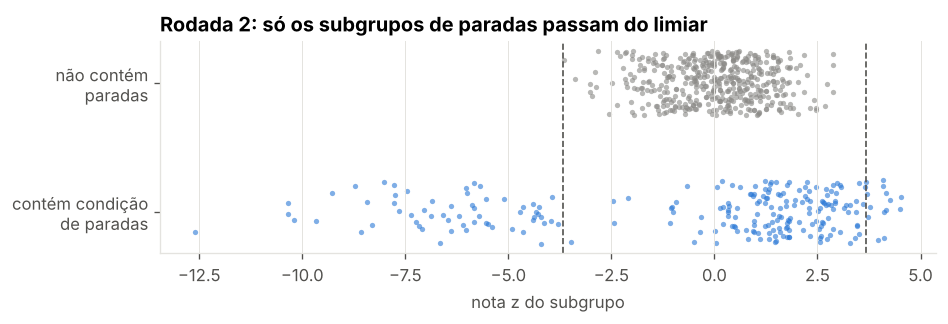

,valor
subgrupos testados,688
passam do limiar,73
"dos que passam, com condição de paradas",73
"dos que passam, com 'parou mais que o pelotão'",60
sem as linhas de 'parou mais': subgrupos testados,590
sem as linhas de 'parou mais': passam do limiar,0


In [7]:
r2 = pd.read_csv(DADOS / "subgrupos_rodada2.csv")
LIMIAR_R2 = 3.68
assert (r2.loc[r2["acima_do_limiar"], "z"].abs() >= LIMIAR_R2).all()

r2["grupo"] = np.where(r2["descricao"].str.contains("d_paradas"),
                       "contém condição de paradas", "não contém paradas")
rng = np.random.default_rng(2026)

fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (g, cor) in enumerate([("contém condição de paradas", "#2a78d6"),
                              ("não contém paradas", "#8a8986")]):
    sub = r2[r2["grupo"] == g]
    ax.scatter(sub["z"], i + rng.uniform(-0.25, 0.25, len(sub)),
               s=10, color=cor, alpha=0.6, linewidths=0)
for x in (-LIMIAR_R2, LIMIAR_R2):
    ax.axvline(x, color=TINTA_2, linestyle="--", linewidth=1)
ax.set_yticks([0, 1], ["contém condição\nde paradas", "não contém\nparadas"])
ax.set_xlabel("nota z do subgrupo")
ax.set_title("Rodada 2: só os subgrupos de paradas passam do limiar")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

passam = r2[r2["acima_do_limiar"]]
sem = pd.read_csv(DADOS / "subgrupos_rodada2_sem_parou_mais.csv")
pd.Series({
    "subgrupos testados": len(r2),
    "passam do limiar": len(passam),
    "dos que passam, com condição de paradas": int(passam["descricao"].str.contains("d_paradas").sum()),
    "dos que passam, com 'parou mais que o pelotão'": int(passam["descricao"].str.contains("parou mais").sum()),
    "sem as linhas de 'parou mais': subgrupos testados": len(sem),
    "sem as linhas de 'parou mais': passam do limiar": int(sem["acima_do_limiar"].sum()),
}).to_frame("valor")

A busca inteira se resume a uma frase: quem para mais que o pelotão termina cerca de 2 posições abaixo do próprio normal (451 linhas). Os outros subgrupos que passaram são o espelho disso ("parou igual" ou "parou menos"). Sem as linhas de "parou mais", nada passa.

Parar mais que o pelotão geralmente é efeito de um problema, e uma parada a mais custa cerca de 20 s de pit lane, o que já basta para perder posições. Além disso, o efeito de nenhum descritor mudou entre os perfis mais do que o acaso explicaria (paradas p = 0,11; composto 0,54; momento da parada 0,84; chuva 0,56; safety car 0,84).

**A causa de fundo é o grão.** Com uma linha por piloto por corrida, a corrida inteira vira um resumo, e não dá para separar uma decisão de estratégia da consequência de um problema. Antes de mudar a base, ainda foram tentados outros caminhos (Parte 4).

## 4. Tentativas intermediárias, ainda no grão piloto × corrida

> **Mensagem:** Seis tentativas de achar um efeito do perfil por outros caminhos; nenhuma se confirmou, e uma delas apontou para o asfalto.

Depois da rodada 2, antes de mudar a base, foram testados outros alvos e outros recortes. As saídas estão no repositório, mas aqui ficam só os resultados, porque nenhuma delas entra no desenho final.

| Tentativa | Pergunta | Resultado |
| --- | --- | --- |
| A1: posição ganha na parada | Cada parada rende posições sobre os vizinhos que param depois? | Padrão firme: parar a até 1,5 s do carro da frente rende +0,44 posição por parada, contra +0,12 na média (o undercut). Perfil sozinho p = 0,50; fase da parada × perfil deu p = 0,003, mas falhou na robustez fixada antes. Não confirmado. |
| A2: companheiro de equipe | Comparar o piloto com o companheiro tira o carro da conta? | 1.159 pares; o efeito detectável ficou pior que antes (0,6 a 1,0 posição). Perfil × estratégia sem sinal (p de 0,07 a 0,38). |
| B: como a corrida se desenrola | O perfil muda a corrida como um todo (largada → chegada, trocas de posição)? | O perfil explica no máximo 4,5% de cada medida por corrida. Largada → chegada: correlação média 0,77, perfil p = 0,12. |
| Pneu × circuito | Quanto do comportamento de pneu é do circuito e quanto do perfil? | O circuito explica 49% da duração do maior stint e 34% do número de paradas; o perfil, 6% e 3%. |
| Degradação | O que explica o desgaste dos pneus? | A abrasão do asfalto (nota Pirelli) explica 5,2% da degradação além do pneu (p = 0,0008); o perfil, 2,4% (p = 0,24). Robusta nas duas eras, nos três compostos e retirando cada circuito. |
| Carro × perfil (ritmo) | Algum carro anda melhor que o próprio normal em certo perfil? | 1.025 carros-corrida; teste geral p = 0,44; nenhum dos 180 pares carro × perfil acima do limiar. |

O padrão se repetia: o circuito importa, o perfil não. Isso levou a recomeçar com uma pergunta e uma base diferentes.

## 5. A mudança para volta × volta (06–07/11)

> **Mensagem:** Com uma linha por volta, aparecem padrões fortes de ultrapassagem e de parada, e o perfil não acrescenta efeito em nenhum subgrupo.

Com uma linha por volta, cada linha descreve a situação naquele momento: distância para o rival, idade do pneu, safety car na pista. Isso exigiu uma coleta nova (`coleta_voltas.py`): posição, tempo de volta, entrada no box, pneu e bandeira de cada piloto em cada volta das 163 corridas. As duas análises usam só as 122 corridas secas.

### 5.1 Duelos: quando o carro de trás consegue passar?

- **Linha:** volta em que um carro termina a até 1,0 s do carro à frente, sem safety car, sem box de nenhum dos dois, a partir da volta 3.
- **Alvo:** o carro de trás está à frente no fim da volta seguinte?
- **Descritores (11):** distância, diferença de idade do pneu, defensor em trem de DRS ou livre, fase, quem largou à frente, composto relativo, posição, relargada, mesma equipe, era e perfil. A era como descritor foi um desvio da proposta, registrado na metodologia.

19.475 voltas de duelo, 26 circuitos; taxa geral de ultrapassagem 13,3%


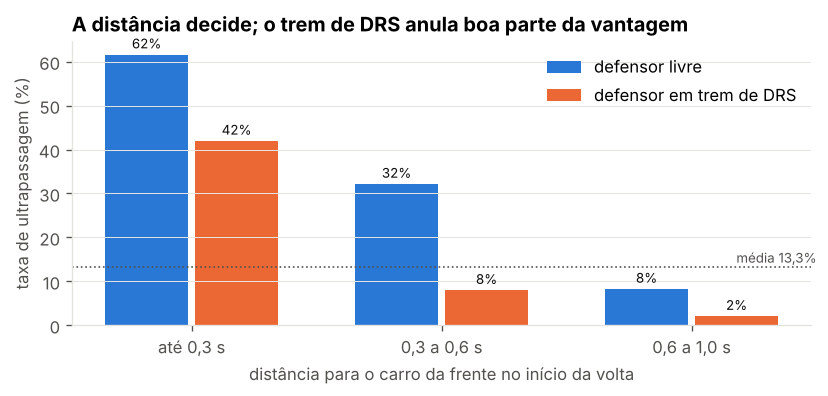

In [8]:
geral_d = duelos["passou"].mean()
print(f"{milhar(len(duelos))} voltas de duelo, {duelos['circuito'].nunique()} circuitos; "
      f"taxa geral de ultrapassagem {pct(geral_d)}")

ordem_dist = ["até 0,3 s", "0,3 a 0,6 s", "0,6 a 1,0 s"]
tx = duelos.groupby(["d_distancia", "d_trem"])["passou"].mean().unstack().reindex(ordem_dist)

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(ordem_dist)); w = 0.36
for j, (col, cor) in enumerate([("defensor livre", "#2a78d6"), ("defensor em trem de DRS", "#eb6834")]):
    barras = ax.bar(x + (j - 0.5) * w, 100 * tx[col], w - 0.03, color=cor, label=col)
    ax.bar_label(barras, labels=[pct(v, 0) for v in tx[col]], padding=2, fontsize=8, color=TINTA)
ax.axhline(100 * geral_d, color=TINTA_2, linestyle=":", linewidth=1)
ax.text(len(ordem_dist) - 0.5, 100 * geral_d + 1, f"média {pct(geral_d)}", ha="right", color=TINTA_2, fontsize=8)
ax.set_xticks(x, ordem_dist); ax.set_xlabel("distância para o carro da frente no início da volta")
ax.set_ylabel("taxa de ultrapassagem (%)")
ax.set_title("A distância decide; o trem de DRS anula boa parte da vantagem")
ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Antes da busca, a pergunta mais simples: a taxa de ultrapassagem muda por perfil?

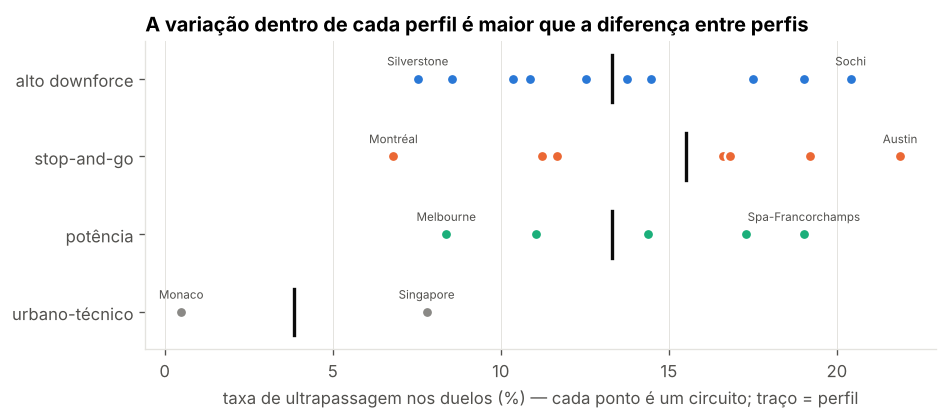

,taxa de ultrapassagem
d_perfil,
alto downforce,"13,3%"
stop-and-go,"15,5%"
potência,"13,3%"
urbano-técnico,"3,8%"


In [9]:
por_circ = (duelos.groupby("circuito")
            .agg(taxa=("passou", "mean"), voltas=("passou", "size"), perfil=("d_perfil", "first")))
por_perfil = duelos.groupby("d_perfil")["passou"].mean().reindex(PERFIS)

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, p in enumerate(PERFIS):
    sub = por_circ[por_circ["perfil"] == p].sort_values("taxa")
    ax.scatter(100 * sub["taxa"], [i] * len(sub), s=46, color=COR[p],
               edgecolors="white", linewidths=1.5, zorder=3)
    ax.plot([100 * por_perfil[p]] * 2, [i - 0.3, i + 0.3], color=TINTA, linewidth=2)
    for nome in (sub.index[0], sub.index[-1]):
        ax.annotate(nome, (100 * sub.loc[nome, "taxa"], i), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=7, color=TINTA_2)
ax.set_yticks(range(len(PERFIS)), PERFIS); ax.invert_yaxis()
ax.set_xlabel("taxa de ultrapassagem nos duelos (%) — cada ponto é um circuito; traço = perfil")
ax.set_title("A variação dentro de cada perfil é maior que a diferença entre perfis")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

por_perfil.map(pct).to_frame("taxa de ultrapassagem")

O teste da taxa por perfil deu p = 0,043, mas só por causa do urbano-técnico (Mônaco tem 0,5%). Os outros três perfis são praticamente iguais, e dentro de cada um a faixa entre circuitos é enorme.

A busca testou combinações de até 3 condições: 947 subgrupos firmes (limiar 8,61), 104 depois de tirar a redundância (um subgrupo só fica se mudar a taxa em pelo menos 3 pontos e 2 erros-padrão em relação a cada versão mais simples dele).

In [10]:
fin_d = pd.read_csv(DADOS / "subgrupos_duelos_finais.csv")
destaques = ["distancia=até 0,3 s", "dif_idade=atacante 10+ voltas mais novo",
             "dif_idade=atacante 10+ voltas mais novo E distancia=até 0,3 s",
             "distancia=até 0,3 s E trem=defensor livre", "trem=defensor em trem de DRS",
             "distancia=0,6 a 1,0 s", "distancia=0,6 a 1,0 s E trem=defensor em trem de DRS"]
t = fin_d[fin_d["descricao"].isin(destaques)][["descricao", "voltas_de_duelo", "circuitos", "taxa", "z"]].copy()
t = t.sort_values("taxa", ascending=False)
t["descricao"] = t["descricao"].map(rotulo)
t["taxa"] = t["taxa"].map(pct); t["z"] = t["z"].round(1)
t.columns = ["subgrupo", "voltas", "circuitos", "taxa de ultrapassagem", "z"]
t

,subgrupo,voltas,circuitos,taxa de ultrapassagem,z
6,"atacante 10+ voltas mais novo e até 0,3 s",343,24,"79,0%",35.9
3,"até 0,3 s e defensor livre",806,26,"61,5%",40.4
0,"até 0,3 s",1171,26,"55,4%",42.5
2,atacante 10+ voltas mais novo,2558,26,"41,1%",41.5
31,defensor em trem de DRS,8299,26,"5,7%",-20.3
20,"0,6 a 1,0 s",12402,26,"5,6%",-25.1
23,"0,6 a 1,0 s e defensor em trem de DRS",5215,26,"2,0%",-23.9


### 5.2 Como a busca decide o que é real

> **Mensagem:** A busca só aceita uma regra se ela superar o que o acaso produz numa busca do mesmo tamanho, medido sorteando os resultados dentro de cada corrida.

Três testes sustentam as conclusões da Etapa 2. Cada um responde a uma pergunta diferente:

| Teste | O que sorteia | Pergunta | Onde é usado |
| --- | --- | --- | --- |
| Permutação | o resultado (alvo), dentro de cada corrida | esta regra existe, ou um efeito desse tamanho aparece por acaso? | todas as buscas de subgrupos |
| Partições | quais circuitos ficam juntos num grupo | a regra muda entre os perfis mais do que entre grupos quaisquer de circuitos? | abrangência por perfil (seção 6.3) |
| Poder | onde e quanto efeito é plantado | se houvesse diferença entre perfis, o teste de partições a veria? | interpretação do "não encontramos diferença" (seção 6.4) |

Os três são testes de **aleatorização**: em vez de supor uma distribuição de livro (como a normal), constroem a distribuição do acaso sorteando os próprios dados. O motivo é que estes dados violam a suposição central dos testes de livro, a de que as linhas são independentes: as voltas de uma mesma corrida e de um mesmo circuito são parecidas entre si. As demonstrações rodam nos dados reais dos duelos, com poucas repetições para caber no notebook, e reproduzem a lógica dos scripts.

#### Teste de permutação: a regra existe?

**A ideia.** Se a distância não tivesse relação nenhuma com a ultrapassagem, tanto faria qual volta de duelo recebeu "passou" e qual recebeu "não passou". Então embaralhamos os resultados e vemos que notas z aparecem nesse mundo em que, por construção, nenhuma regra tem efeito.

**Por que dentro da corrida.** O embaralhamento troca os resultados só entre voltas da mesma corrida. Assim, cada corrida mantém o seu número de ultrapassagens (uma corrida caótica continua caótica), e só some a ligação entre as condições do duelo e o resultado. Se o embaralhamento fosse na base inteira, o mundo falso apagaria também as diferenças entre corridas, e o teste ficaria otimista demais.

**Passo 1: uma regra só.** A nota z de "atacante a até 0,3 s" nos dados reais, comparada com a nota z da mesma regra em 300 embaralhamentos. Para comparação, um descritor inventado: cada volta recebe "cara" ou "coroa" ao acaso, e a regra "cara" não pode ter efeito real.

In [11]:
import sys
from itertools import combinations

rng_demo = np.random.default_rng(2026)
y_d = duelos_demo = None  # definido abaixo

base_d = pd.read_csv(DADOS / "base_duelos.csv")
y_d = base_d["passou"].to_numpy(float)
corrida_d = pd.factorize(base_d["ano"].astype(str) + "_" + base_d["round"].astype(str))[0]
circ_d = pd.factorize(base_d["circuito"])[0]
ordem_corrida = np.argsort(corrida_d, kind="stable")


def embaralha_na_corrida(y, rng):
    """Troca os resultados só entre voltas da mesma corrida."""
    idx = np.lexsort((rng.random(len(y)), corrida_d))
    novo = np.empty_like(y)
    novo[ordem_corrida] = y[idx]
    return novo


def notas_z(M, y):
    """Nota z de cada subgrupo (linhas de M): (média no subgrupo − média geral) × √n / desvio."""
    return (M @ (y - y.mean())) / np.sqrt(M.sum(1)) / y.std(ddof=1)


ate_03 = (base_d["d_distancia"] == "até 0,3 s").to_numpy()
moeda = rng_demo.random(len(base_d)) < 0.5            # descritor inventado
M1 = np.array([ate_03, moeda], dtype=np.float32)

z_real = notas_z(M1, y_d)
z_acaso = np.array([notas_z(M1, embaralha_na_corrida(y_d, rng_demo)) for _ in range(300)])
lim_1 = np.quantile(np.abs(z_acaso[:, 0]), 0.95)

pd.DataFrame({
    "z nos dados reais": z_real.round(2),
    "95% do |z| no acaso (mesma regra)": np.quantile(np.abs(z_acaso), 0.95, axis=0).round(2),
}, index=["atacante a até 0,3 s", "descritor inventado (moeda)"])

,z nos dados reais,95% do |z| no acaso (mesma regra)
"atacante a até 0,3 s",42.52,3.07
descritor inventado (moeda),0.47,1.52


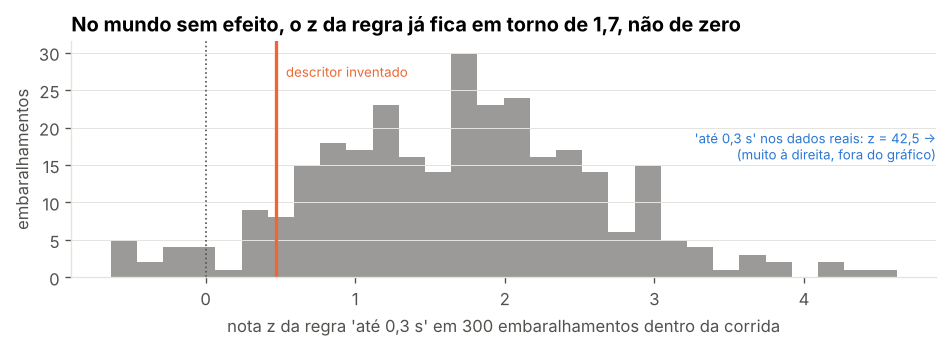

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(z_acaso[:, 0], bins=30, color="#8a8986", alpha=0.85)
ax.axvline(0, color=TINTA_2, linestyle=":", linewidth=1)
ax.axvline(z_real[1], color="#eb6834", linewidth=2)
ax.annotate("descritor inventado", (z_real[1], ax.get_ylim()[1] * 0.85), xytext=(6, 0),
            textcoords="offset points", color="#eb6834", fontsize=8)
ax.annotate(f"'até 0,3 s' nos dados reais: z = {num(z_real[0], 1)} →\n(muito à direita, fora do gráfico)",
            (ax.get_xlim()[1], ax.get_ylim()[1] * 0.5), ha="right", color="#2a78d6", fontsize=8)
ax.set_xlabel("nota z da regra 'até 0,3 s' em 300 embaralhamentos dentro da corrida")
ax.set_ylabel("embaralhamentos")
ax.set_title(f"No mundo sem efeito, o z da regra já fica em torno de {num(np.median(z_acaso[:, 0]), 1)}, não de zero")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Nos dados reais, o z de "até 0,3 s" é 42,5, muito longe de tudo o que o acaso produziu. A regra inventada fica dentro da nuvem do acaso, como deve ficar.

O gráfico mostra também por que o teste é necessário. Num teste de livro, com voltas independentes, o z de uma regra sem efeito ficaria centrado em zero, e o limite de 95% seria |z| = 1,96. Aqui, mesmo sem efeito nenhum, o z de "até 0,3 s" fica centrado acima de zero e passa de 3 com alguma frequência. O motivo é a composição das corridas: duelos a até 0,3 s acontecem mais em corridas com muitas ultrapassagens, e o embaralhamento dentro da corrida preserva isso. Um teste de livro atribuiria essa parte à regra; a permutação a desconta, porque ela aparece também no mundo sem efeito. Para a moeda, que se espalha igual por todas as corridas, o limite fica abaixo de 2. A permutação mede o limite certo para cada regra nos próprios dados, em vez de supor o 1,96.

**Passo 2: muitas regras ao mesmo tempo.** A busca não testa uma regra, testa centenas ou milhares. Quanto mais regras, maior a chance de alguma ter z alto só por sorte (como jogar muitas moedas: alguma vai dar muitas caras seguidas). A correção é olhar, em cada embaralhamento, o **maior** |z| entre todas as regras testadas, e usar o percentil 95 desses máximos como limiar. Assim, o acaso só produz uma regra acima do limiar em 5% das buscas inteiras, não em 5% das regras.

A demonstração usa os 9 descritores de situação de corrida dos duelos (sem perfil e sem era), com as mesmas exigências da busca real: 100 voltas, 4 ou mais circuitos, nenhum circuito com mais de 40% das linhas.

In [13]:
DESC_DEMO = ["d_dif_idade", "d_dif_composto", "d_distancia", "d_trem", "d_largada",
             "d_fase", "d_relargada", "d_posicao", "d_mesma_equipe"]
condicoes = [(c, v) for c in DESC_DEMO for v in sorted(base_d[c].unique())]


def subgrupos_elegiveis(profundidade):
    grupos = []
    for k in range(1, profundidade + 1):
        for comb in combinations(condicoes, k):
            if len({c for c, _ in comb}) < k:
                continue
            m = np.ones(len(base_d), dtype=bool)
            for c, v in comb:
                m &= base_d[c].to_numpy() == v
            n = m.sum()
            if n < 100:
                continue
            cont = np.bincount(circ_d[m])
            if (cont > 0).sum() < 4 or cont.max() > 0.4 * n:
                continue
            grupos.append(m)
    return np.array(grupos, dtype=np.float32)


resultado, maximos = [], {}
for prof in (1, 2):
    M = subgrupos_elegiveis(prof)
    mx = np.array([np.abs(notas_z(M, embaralha_na_corrida(y_d, rng_demo))).max() for _ in range(200)])
    maximos[prof] = mx
    resultado.append({"regras testadas": f"até {prof} condição(ões)", "quantas": len(M),
                      "limiar (95% do maior |z|)": round(np.quantile(mx, 0.95), 2),
                      "regras reais acima do limiar": int((np.abs(notas_z(M, y_d)) > np.quantile(mx, 0.95)).sum())})
resultado.insert(0, {"regras testadas": "uma regra só ('até 0,3 s')", "quantas": 1,
                     "limiar (95% do maior |z|)": round(lim_1, 2), "regras reais acima do limiar": 1})
resultado.append({"regras testadas": "busca real (até 3 condições, com perfil e era)", "quantas": "milhares",
                  "limiar (95% do maior |z|)": 8.61, "regras reais acima do limiar": "947 firmes"})
pd.DataFrame(resultado).set_index("regras testadas")

,quantas,limiar (95% do maior |z|),regras reais acima do limiar
regras testadas,,,
"uma regra só ('até 0,3 s')",1,3.07,1
até 1 condição(ões),24,3.76,18
até 2 condição(ões),276,4.73,189
"busca real (até 3 condições, com perfil e era)",milhares,8.61,947 firmes


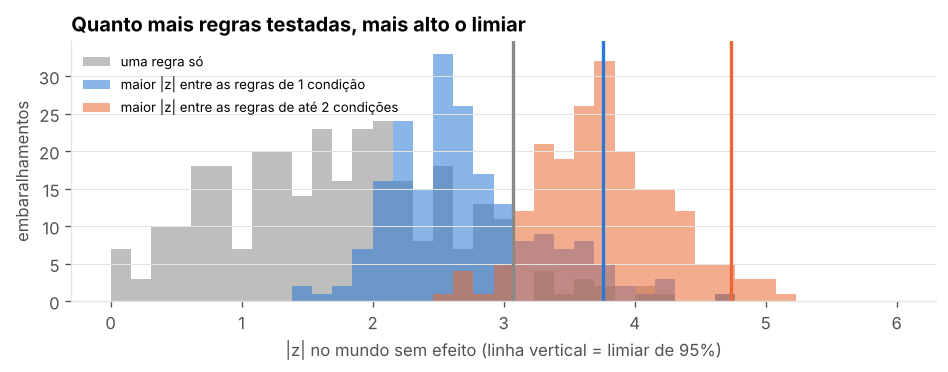

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.2))
series = [("uma regra só", np.abs(z_acaso[:, 0]), "#8a8986"),
          ("maior |z| entre as regras de 1 condição", maximos[1], "#2a78d6"),
          ("maior |z| entre as regras de até 2 condições", maximos[2], "#eb6834")]
bins = np.linspace(0, max(maximos[2].max(), 6), 40)
for nome, valores, cor in series:
    ax.hist(valores, bins=bins, color=cor, alpha=0.55, label=nome)
    ax.axvline(np.quantile(valores, 0.95), color=cor, linewidth=2)
ax.set_xlabel("|z| no mundo sem efeito (linha vertical = limiar de 95%)")
ax.set_ylabel("embaralhamentos")
ax.set_title("Quanto mais regras testadas, mais alto o limiar")
ax.legend(fontsize=8); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

O limiar sobe com o número de regras testadas. A busca real tem milhares de regras de até 3 condições e também sorteia o perfil entre circuitos e a era entre corridas do mesmo circuito; como os circuitos diferem muito entre si, regras com perfil ganham z altos mesmo no acaso, e o limiar chega a 8,61. Uma regra só é aceita se passar desse valor, o que torna o critério bem exigente.

**Em uma frase:** o limiar é o percentil 95 do maior |z| obtido em 500 permutações do alvo dentro de cada corrida. Comparar com o máximo de toda a busca controla os múltiplos testes, e embaralhar dentro da corrida respeita a dependência entre voltas da mesma corrida.

### 5.3 Assinatura do perfil: as corridas de cada perfil têm um jeito próprio?

Entre os duelos e a decisão de parar, foi testado o caminho inverso: em vez de usar o perfil para explicar a corrida, usar a corrida para reconhecer o perfil. Alvo: "a corrida é do perfil X", uma busca por perfil, nas 122 corridas secas. Descritores, em terços: taxa de ultrapassagem, trocas de posição por volta, largada → chegada, paradas, maior stint, degradação, abandonos, safety car e era.

**Resultado: nenhum subgrupo firme em nenhum perfil.** O urbano-técnico é visivelmente diferente (ultrapassagem 4,5%, largada → chegada 0,87), mas tem só 7 corridas secas e não passa do limiar (z 2,95 contra 4,12). Os outros três perfis têm corridas parecidas entre si.

### 5.4 Decisão de parar: em que situações as equipes param?

- **Linha:** um piloto em uma volta. **Alvo:** entrou no box e trocou de pneu nesta volta?
- **Descritores (12):** medidos no fim da volta anterior (o que a equipe sabia na hora): safety car/VSC, idade do pneu, paradas já feitas, composto, posição, fase, distância para os carros da frente e de trás, rival que acabou de parar, a "janela" de parada, era e perfil. Busca de até 2 condições, por custo computacional.
- **Correção do safety car:** na primeira versão, "safety car" valia para a volta inteira e para todos os pilotos, o que marcava como neutralizadas 1.338 voltas em que aquele piloto não estava sob safety car e diluía a taxa. Passou a valer "safety car ou VSC ativo no momento da decisão" (entrada do box para quem parou, fim da volta para quem não parou). O efeito subiu de +6,8 para +11,2 p.p. As 97 voltas com bandeira vermelha saíram, porque sob vermelha todos trocam de pneu livremente (exclusão decidida depois de ver os números).

121.075 voltas, 3.528 paradas; taxa geral 2,91% por volta


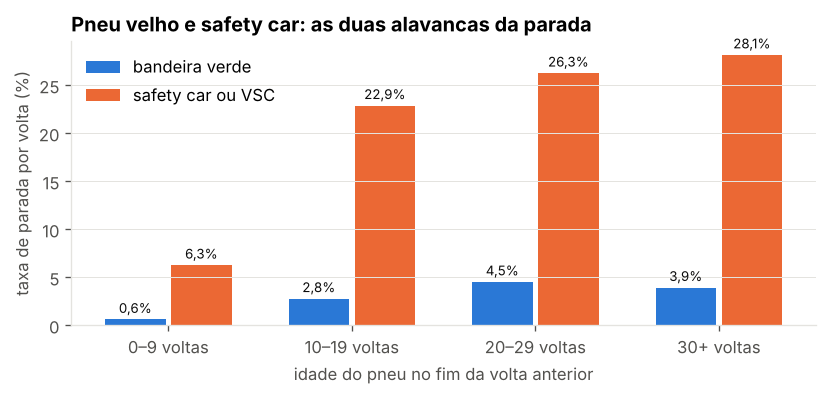

,taxa de parada por volta
d_perfil,
alto downforce,"3,08%"
stop-and-go,"2,97%"
potência,"2,81%"
urbano-técnico,"1,90%"


In [15]:
paradas = pd.read_csv(DADOS / "base_decisao_parada.csv")
geral_p = paradas["parou"].mean()
print(f"{milhar(len(paradas))} voltas, {milhar(int(paradas['parou'].sum()))} paradas; "
      f"taxa geral {pct(geral_p, 2)} por volta")

ordem_idade = ["0–9 voltas", "10–19 voltas", "20–29 voltas", "30+ voltas"]
tx = paradas.groupby(["d_idade_pneu", "d_neutralizacao"])["parou"].mean().unstack().reindex(ordem_idade)

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(ordem_idade)); w = 0.36
for j, (col, cor) in enumerate([("bandeira verde", "#2a78d6"), ("safety car ou VSC", "#eb6834")]):
    barras = ax.bar(x + (j - 0.5) * w, 100 * tx[col], w - 0.03, color=cor, label=col)
    ax.bar_label(barras, labels=[pct(v, 1) for v in tx[col]], padding=2, fontsize=8, color=TINTA)
ax.set_xticks(x, ordem_idade); ax.set_xlabel("idade do pneu no fim da volta anterior")
ax.set_ylabel("taxa de parada por volta (%)")
ax.set_title("Pneu velho e safety car: as duas alavancas da parada")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

paradas.groupby("d_perfil")["parou"].mean().reindex(PERFIS).map(lambda v: pct(v, 2)).to_frame("taxa de parada por volta")

In [16]:
fin_p = pd.read_csv(DADOS / "subgrupos_decisao_parada_finais.csv")
print(f"{len(fin_p)} subgrupos finais depois da redundância (limiar |z| 7,48)")
t = fin_p[~fin_p["tem_perfil"]].sort_values("media", ascending=False)
t = pd.concat([t.head(7), t.tail(4)])[["descricao", "linhas", "circuitos", "media", "z"]].copy()
t["descricao"] = t["descricao"].map(rotulo)
t["media"] = t["media"].map(lambda v: pct(v, 1)); t["z"] = t["z"].round(1)
t.columns = ["subgrupo", "voltas", "circuitos", "taxa de parada", "z"]
t

63 subgrupos finais depois da redundância (limiar |z| 7,48)


,subgrupo,voltas,circuitos,taxa de parada,z
19,pneu 30+ voltas e safety car ou VSC,270,18,"28,1%",24.7
11,pneu 20–29 voltas e safety car ou VSC,518,21,"26,3%",31.6
34,safety car ou VSC e rival de trás parou,240,24,"23,3%",18.8
4,pneu 10–19 voltas e safety car ou VSC,1176,25,"22,9%",40.7
41,safety car ou VSC e rival da frente parou,212,22,"22,2%",16.7
1,mais de 3 s do carro da frente e safety car ou VSC,1651,26,"20,8%",43.3
12,top 5 e rival de trás parou,807,26,"20,7%",30.0
45,2+ paradas feitas,25282,26,"1,2%",-15.9
20,pneu 0–9 voltas,42923,26,"1,0%",-24.1
56,primeiro terço e 1 parada feitas,7506,26,"0,7%",-11.4


### 5.5 O perfil acrescenta alguma coisa?

Na busca apareceram subgrupos como "stop-and-go e a até 0,3 s", firmes e com taxas altas. Mas "a até 0,3 s" já tem 55% de ultrapassagem em qualquer pista: o subgrupo pode estar só herdando o efeito da distância. Em dados sintéticos sem nenhum efeito de perfil, dezenas de subgrupos "perfil e condição" passavam na busca por esse motivo.

Por isso, cada subgrupo firme com perfil foi comparado com a mesma condição nos outros perfis, com limiar próprio obtido trocando os perfis entre os 26 circuitos.

In [17]:
def conta_acrescenta(df):
    com = df[df["tem_perfil"]]
    return pd.Series({"subgrupos finais com perfil": len(com),
                      "em que o perfil acrescenta": int((com["perfil_acrescenta"] == True).sum())})

pd.DataFrame({"duelos": conta_acrescenta(fin_d), "decisão de parar": conta_acrescenta(fin_p)})

,duelos,decisão de parar
subgrupos finais com perfil,19,1
em que o perfil acrescenta,0,0


Contando todos os firmes (antes da redundância), o perfil acrescentou efeito em 0 de 197 subgrupos nos duelos e em 0 de 32 nas paradas (maior z 4,83 contra limiar 7,77). Todos os padrões encontrados são de situação de corrida, não de tipo de pista.

**Limitações:** nos duelos, o carro mais rápido não está controlado (só por quem largou à frente), a distância é medida no fim da volta e não no ponto do DRS, e um erro pequeno do defensor conta como ultrapassagem. Nas paradas, parte do efeito "rival parou" pode vir do safety car. As duas análises usam só corridas secas e mostram associação, não causa.

## 6. A reformulação: padrões gerais primeiro, perfis depois (10/11)

> **Mensagem:** As regras globais são estáveis e valem em todos os perfis, dentro do que 26 circuitos permitem detectar.

Como o perfil não acrescentou efeito em nenhum subgrupo, as funções foram separadas:

- a **SD** encontra os padrões com todos os circuitos juntos e sem o perfil como descritor (resultado central);
- a **tipologia** é usada depois, para medir se esses padrões valem igualmente nos perfis (abrangência).

### 6.1 A SD dentro de cada perfil

Primeiro, o perfil passou de descritor a recorte: a busca foi refeita separadamente dentro de cada perfil (alto downforce, stop-and-go, potência), com os mesmos critérios, e comparada com a busca global.

- Dentro de cada perfil, a SD encontra praticamente as mesmas regras do global: a correlação entre o efeito local e o global das mesmas regras fica entre 0,97 e 0,99, e nenhuma regra firme local tem sentido oposto ao global.
- As poucas regras que só aparecem num perfil (até 13 no stop-and-go) não indicam padrão próprio: a variação do efeito entre os perfis não supera a de grupos de circuitos sorteados (p = 0,49 nas paradas e 0,54 nos duelos, pelo teste de partições da seção 6.3).

Com isso, a SD passou a rodar com todos os circuitos juntos, e o perfil passou a ser usado só para medir a abrangência das regras encontradas.

### 6.2 Regras globais consolidadas

Com a SD global, para reduzir os 104 e 63 subgrupos a uma lista curta, foi usado o **CN2-SD**: entra a regra de maior z; as voltas que ela já explica passam a pesar menos; repete até nenhuma regra passar do limiar ou chegar a 8 regras acima da média e 3 abaixo. Ajuste decidido depois da primeira rodada: quando uma regra entra, saem da disputa as variações dela. O intervalo de 95% vem de sortear os 26 circuitos com reposição, porque as voltas de um mesmo circuito são parecidas entre si.

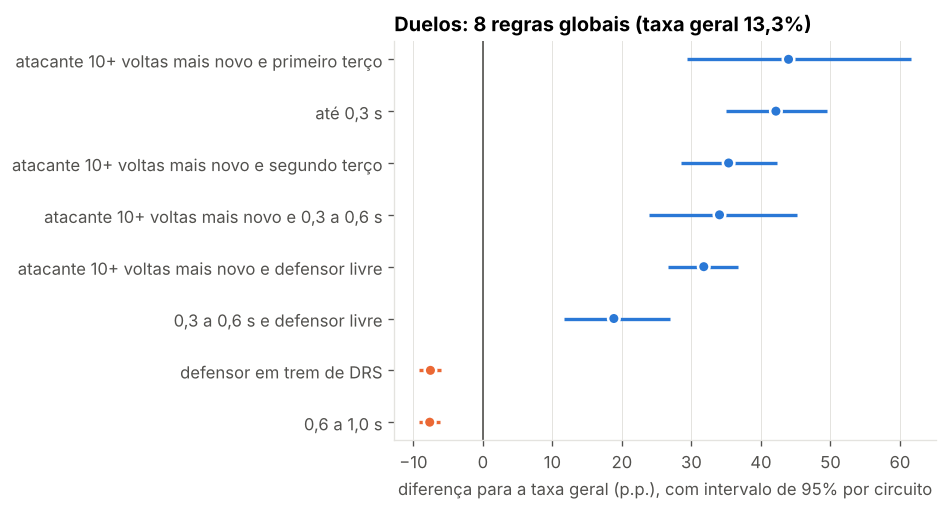

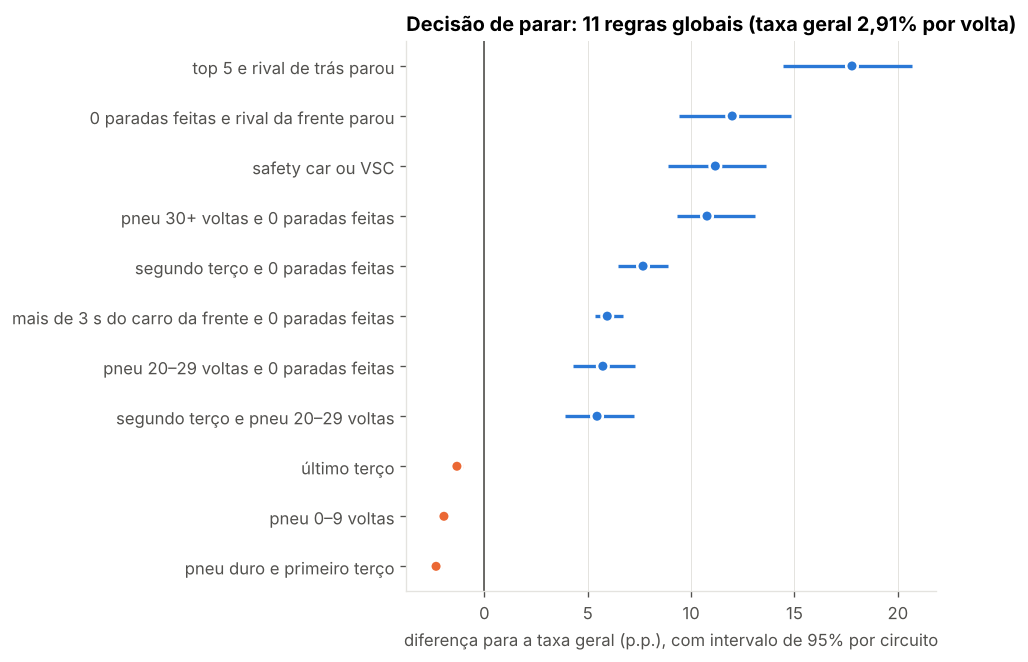

In [18]:
def grafico_regras(df, titulo, unidade="p.p."):
    df = df.sort_values("dif_pp")
    y = np.arange(len(df))
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(df) + 1))
    cores = np.where(df["dif_pp"] > 0, "#2a78d6", "#eb6834")
    ax.hlines(y, df["dif_pp_ic_inf"], df["dif_pp_ic_sup"], color=cores, linewidth=2)
    ax.scatter(df["dif_pp"], y, color=cores, s=48, zorder=3, edgecolors="white", linewidths=1.5)
    ax.axvline(0, color=TINTA_2, linewidth=1)
    ax.set_yticks(y, [rotulo(r) for r in df["regra"]])
    ax.set_xlabel(f"diferença para a taxa geral ({unidade}), com intervalo de 95% por circuito")
    ax.set_title(titulo); ax.grid(axis="y", visible=False)
    plt.tight_layout(); plt.show()

rg_d = pd.read_csv(DADOS / "regras_globais_duelos.csv")
rg_p = pd.read_csv(DADOS / "regras_globais_parada.csv")
grafico_regras(rg_d, f"Duelos: 8 regras globais (taxa geral {pct(geral_d)})")
grafico_regras(rg_p, f"Decisão de parar: 11 regras globais (taxa geral {pct(geral_p, 2)} por volta)")

In [19]:
def tabela_regras(df):
    t = df[["ordem", "regra", "taxa_pct", "dif_pp", "voltas", "pct_positivos_acumulado",
            "taxa_2018_21_pct", "taxa_2022_mais_pct", "circuitos_no_sentido"]].copy()
    t["regra"] = t["regra"].map(rotulo)
    for c in ["taxa_pct", "dif_pp", "pct_positivos_acumulado", "taxa_2018_21_pct", "taxa_2022_mais_pct"]:
        t[c] = t[c].round(1)
    t.columns = ["#", "regra", "taxa %", "dif. p.p.", "voltas", "% acumulado dos casos",
                 "2018–21 %", "2022+ %", "circuitos no sentido"]
    return t.set_index("#")

display(tabela_regras(rg_d))
tabela_regras(rg_p)

,regra,taxa %,dif. p.p.,voltas,% acumulado dos casos,2018–21 %,2022+ %,circuitos no sentido
#,,,,,,,,
1,"até 0,3 s",55.4,42.2,1171,25.1,60.2,53.6,16 de 16
2,atacante 10+ voltas mais novo e defensor livre,45.0,31.8,2038,51.8,38.6,49.8,25 de 25
3,"0,3 a 0,6 s e defensor livre",32.1,18.8,3183,74.5,39.0,29.2,21 de 25
4,atacante 10+ voltas mais novo e segundo terço,48.6,35.4,1123,76.0,46.0,50.1,22 de 22
5,"atacante 10+ voltas mais novo e 0,3 a 0,6 s",47.3,34.0,1040,77.4,50.3,45.8,20 de 21
6,atacante 10+ voltas mais novo e primeiro terço,57.2,44.0,152,77.5,50.0,62.8,2 de 2
7,"0,6 a 1,0 s",5.6,-7.6,12402,NaN,6.9,4.9,26 de 26
8,defensor em trem de DRS,5.7,-7.5,8299,NaN,7.2,5.2,25 de 26


,regra,taxa %,dif. p.p.,voltas,% acumulado dos casos,2018–21 %,2022+ %,circuitos no sentido
#,,,,,,,,
1,safety car ou VSC,14.1,11.2,4579,18.3,12.2,15.6,24 de 26
2,segundo terço e 0 paradas feitas,10.6,7.7,8046,39.7,11.2,10.1,25 de 25
3,mais de 3 s do carro da frente e 0 paradas feitas,8.9,5.9,12214,51.7,7.9,9.8,26 de 26
4,segundo terço e pneu 20–29 voltas,8.4,5.5,9695,61.0,8.4,8.3,23 de 26
5,pneu 30+ voltas e 0 paradas feitas,13.7,10.8,2565,61.4,13.3,14.0,20 de 20
6,top 5 e rival de trás parou,20.7,17.8,807,62.7,16.7,23.5,19 de 19
7,0 paradas feitas e rival da frente parou,14.9,12.0,973,64.0,11.1,17.8,19 de 19
8,pneu 20–29 voltas e 0 paradas feitas,8.6,5.7,6639,65.2,9.3,8.0,21 de 25
9,pneu 0–9 voltas,1.0,-2.0,42923,NaN,0.8,1.1,26 de 26


Todas as regras mantêm o sentido nas duas eras e ao retirar qualquer circuito, e nenhum intervalo cruza zero. Nos duelos, as 3 primeiras regras cobrem 74,5% das ultrapassagens; nas paradas, as 8 acima da média cobrem 65% das paradas.

**Em palavras:** passa-se quando se está muito perto, com pneu bem mais novo e com o defensor fora de um trem de DRS. Para-se sob safety car, com pneu velho sem ter parado, no meio da corrida e em reação ao rival que acabou de parar (no top 5, a parada do rival de trás leva à parada em 1 de cada 5 voltas: a defesa contra o undercut).

### 6.3 Como medir se uma regra muda entre perfis: o teste de partições

Este teste vem **depois** da busca, com as regras já encontradas, e não mexe em resultado nenhum: cada volta continua com o resultado verdadeiro.

**A ideia.** Os perfis são um jeito de dividir os 26 circuitos em grupos de 11, 8, 5 e 2. Se essa divisão captura algo real, o efeito das regras deve variar mais entre os perfis do que entre grupos de circuitos montados ao acaso, com os mesmos tamanhos.

**Por que sortear circuitos, e não voltas.** O perfil é uma característica do circuito: todas as voltas de Monza são "potência". Para saber se o perfil importa, o que se troca de grupo é o circuito inteiro. Trocar voltas uma a uma fingiria que há 19 mil observações sobre o perfil, quando há 26.

**A medida (Q/gl).** Para cada grupo, calcula-se o efeito da regra (taxa na regra menos a taxa do grupo). Q soma o quanto o efeito de cada grupo se afasta da média, dando mais peso a grupos com mais dados; gl é o número de grupos menos 1. Quanto maior o Q/gl, mais os grupos diferem.

O exemplo usa a regra "até 0,3 s", a que mais pareceu variar entre perfis, com as funções do próprio script `abrangencia_regras_perfil.py`.

In [20]:
sys.path.insert(0, "../src")
from abrangencia_regras_perfil import mascara, somas, q_por_gl
from poder_teste_particoes import q_efeito

circuitos = np.array(sorted(base_d["circuito"].unique()))
perfil_c = base_d.drop_duplicates("circuito").set_index("circuito")["d_perfil"].reindex(circuitos).to_numpy()
tamanhos = pd.Series(perfil_c).value_counts()
testados = sorted(g for g in tamanhos.index if g != "urbano-técnico")
rotulos = np.concatenate([[g] * k for g, k in tamanhos.items()])

regra = "distancia=até 0,3 s"
m_regra = mascara(base_d, regra)
tot, _ = somas(base_d, m_regra, "passou", circuitos)   # por circuito: voltas, passou, voltas na regra, passou na regra


def q_efeito_regra(rotulo_por_circuito):
    grupos = np.array([tot[rotulo_por_circuito == g].sum(0) for g in testados])
    return q_por_gl(grupos, 100)[1]


def efeitos_por_grupo(rotulo_por_circuito):
    out = {}
    for g in testados:
        n, y, mm, ym = tot[rotulo_por_circuito == g].sum(0)
        out[g] = 100 * (ym / mm - y / n)
    return out


rng_part = np.random.default_rng(2026)
q_real = q_efeito_regra(perfil_c)
particoes = [rng_part.permutation(rotulos) for _ in range(2000)]
q_ref = np.array([q_efeito_regra(r) for r in particoes])
p_part = (np.sum(q_ref >= q_real) + 1) / (len(q_ref) + 1)

exemplo = particoes[0]
tab = pd.DataFrame({"perfis reais": efeitos_por_grupo(perfil_c),
                    "uma partição sorteada": efeitos_por_grupo(exemplo)}).round(1)
tab.index = [f"grupo com o tamanho de '{g}' ({tamanhos[g]} circuitos)" for g in tab.index]
display(tab.rename_axis("efeito de 'até 0,3 s' (p.p.)"))
print("Circuitos no grupo sorteado com o tamanho de 'potência':",
      ", ".join(circuitos[exemplo == "potência"]))
print(f"\nQ/gl dos perfis reais: {num(q_real, 1)}; mediana nas partições sorteadas: {num(np.median(q_ref), 1)}; "
      f"95% das sorteadas: {num(np.quantile(q_ref, 0.95), 1)}; p = {num(p_part, 3)}")

,perfis reais,uma partição sorteada
"efeito de 'até 0,3 s' (p.p.)",,
grupo com o tamanho de 'alto downforce' (11 circuitos),51.2,48.0
grupo com o tamanho de 'potência' (5 circuitos),40.2,49.2
grupo com o tamanho de 'stop-and-go' (8 circuitos),30.6,30.7


Circuitos no grupo sorteado com o tamanho de 'potência': Austin, Barcelona, Jeddah, Sochi, Spa-Francorchamps

Q/gl dos perfis reais: 39,1; mediana nas partições sorteadas: 11,4; 95% das sorteadas: 37,4; p = 0,045


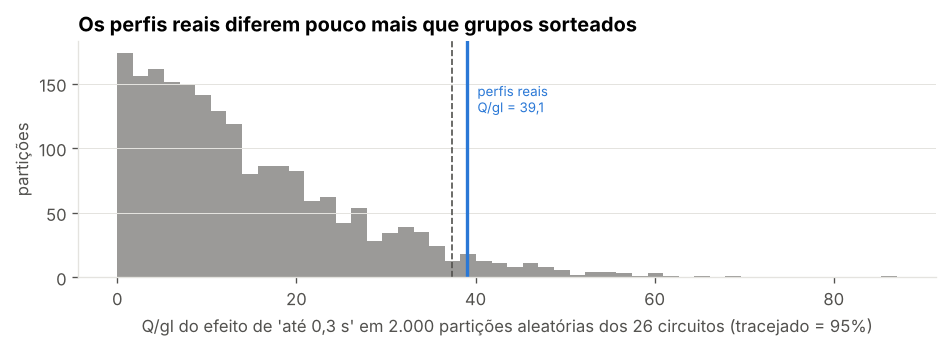

In [21]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(q_ref, bins=50, color="#8a8986", alpha=0.85)
ax.axvline(q_real, color="#2a78d6", linewidth=2)
ax.axvline(np.quantile(q_ref, 0.95), color=TINTA_2, linestyle="--", linewidth=1)
ax.annotate(f"perfis reais\nQ/gl = {num(q_real, 1)}", (q_real, ax.get_ylim()[1] * 0.7), xytext=(6, 0),
            textcoords="offset points", color="#2a78d6", fontsize=8)
ax.set_xlabel("Q/gl do efeito de 'até 0,3 s' em 2.000 partições aleatórias dos 26 circuitos (tracejado = 95%)")
ax.set_ylabel("partições")
ax.set_title("Os perfis reais diferem pouco mais que grupos sorteados")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Duas coisas aparecem aqui:

1. **Grupos sorteados também diferem bastante.** A mediana do Q/gl nas partições sorteadas fica em torno de 11, longe do 1 que se esperaria se os circuitos fossem todos iguais. Isso é a variação natural entre circuitos, e é por isso que o perfil precisa ser comparado com partições sorteadas, e não com zero.
2. **Para esta regra, os perfis reais ficam no limite** (p ≈ 0,045). Mas foram testadas 19 regras e dois aspectos de cada uma (frequência e efeito). Corrigindo para isso, com o mesmo truque do máximo usado na permutação, o p vai para 0,51. Por isso a diferença fica como exploratória.

Para as demais regras, os perfis reais ficam no meio da nuvem das partições sorteadas (seção 6.5).

**Em uma frase:** o teste de partições compara a heterogeneidade do efeito entre os perfis reais (Q/gl) com a de 2.000 partições aleatórias dos 26 circuitos com os mesmos tamanhos. Como a unidade sorteada é o circuito, a variação natural entre circuitos já está na referência: o teste pergunta se a tipologia separa os circuitos melhor que um agrupamento ao acaso.

### 6.4 O teste de partições veria uma diferença, se ela existisse? O teste de poder

"Não encontrar diferença" pode significar que não há diferença ou que o teste é fraco demais para vê-la. O teste de poder separa as duas coisas **plantando uma diferença conhecida** e vendo se o teste de partições a encontra.

**Uma repetição, passo a passo:**

1. Sorteia-se uma divisão dos circuitos com os tamanhos reais (o efeito é plantado num grupo sorteado, e não num perfil real, para não misturar o plantado com diferenças que já existem entre os perfis).
2. Nas voltas da regra dentro de um grupo, parte dos "não passou" vira "passou", de modo que a taxa da regra nesse grupo suba Δ pontos.
3. Roda-se o teste de partições e anota-se se ele detectou (p < 0,05).

Repetindo 200 vezes para cada regra, tamanho de grupo e Δ, o **poder** é a porcentagem de repetições em que a diferença plantada foi detectada. A convenção é exigir 80%. Abaixo, uma única repetição feita aqui, com +30 p.p. plantados em "até 0,3 s" num grupo sorteado de 8 circuitos.

In [22]:
rng_poder = np.random.default_rng(7)
cod = pd.Categorical(base_d["circuito"], categories=circuitos).codes
nc = np.bincount(cod, minlength=len(circuitos)).astype(float)
mc = np.bincount(cod, weights=m_regra, minlength=len(circuitos))
H_ref = np.stack([np.stack([(p == t) for t in testados]) for p in particoes[:1000]]).astype(float)


def uma_repeticao(delta_pp, grupo="stop-and-go"):
    pseudo = rng_poder.permutation(rotulos)                  # divisão sorteada
    no_grupo = (pseudo == grupo)[cod]
    alvo = m_regra & no_grupo
    taxa = y_d[alvo].mean()
    y = y_d.copy()
    prob = min(delta_pp / 100 / (1 - taxa), 1.0)
    cand = np.flatnonzero(alvo & (y_d == 0))
    y[cand[rng_poder.random(len(cand)) < prob]] = 1.0          # efeito plantado
    tot_y = np.column_stack([nc, np.bincount(cod, weights=y, minlength=len(circuitos)),
                             mc, np.bincount(cod, weights=y * m_regra, minlength=len(circuitos))])
    H = np.stack([(pseudo == t) for t in testados]).astype(float)
    q_obs = q_efeito(H @ tot_y, 100)
    q_r = q_efeito(H_ref @ tot_y, 100)
    return (np.sum(q_r >= q_obs) + 1) / (len(q_r) + 1), circuitos[pseudo == grupo]


p_rep, grupo_rep = uma_repeticao(30)
print("Grupo sorteado (8 circuitos):", ", ".join(grupo_rep))
print(f"p desta repetição com +30 p.p. plantados: {num(p_rep, 3)} -> "
      f"{'detectou' if p_rep < 0.05 else 'não detectou'}")

Grupo sorteado (8 circuitos): Austin, Barcelona, Imola, Jeddah, Sakhir, Shanghai, Singapore, Zandvoort
p desta repetição com +30 p.p. plantados: 0,005 -> detectou


O resultado de uma repetição isolada varia com o grupo sorteado; o poder é a proporção ao longo de 200 delas. As curvas abaixo vêm do script `poder_teste_particoes.py` e mostram, para três regras, como o poder cresce com o tamanho da diferença plantada.

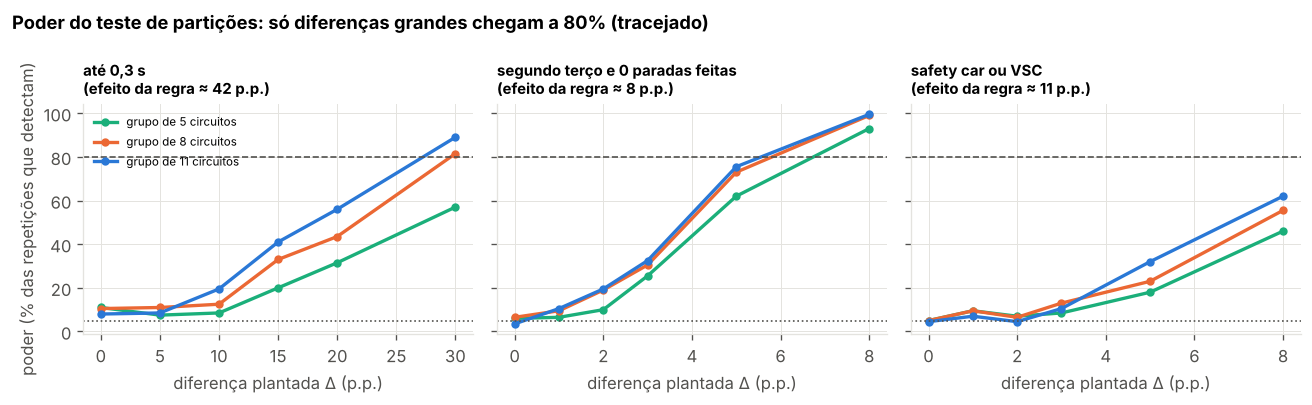

In [23]:
poder_d = pd.read_csv(DADOS / "abrangencia/poder_duelos.csv")
poder_p = pd.read_csv(DADOS / "abrangencia/poder_parada.csv")
exemplos = [(poder_d, "distancia=até 0,3 s"),
            (poder_p, "fase=segundo terço E paradas_feitas=0 paradas"),
            (poder_p, "neutralizacao=safety car ou VSC")]
cores_tam = {5: "#1baf7a", 8: "#eb6834", 11: "#2a78d6"}

fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (tab, reg) in zip(axs, exemplos):
    s = tab[tab["regra"] == reg]
    for k, cor in cores_tam.items():
        c = s[s["circuitos_no_grupo"] == k].sort_values("delta_pp")
        ax.plot(c["delta_pp"], 100 * c["poder"], marker="o", color=cor, linewidth=2, markersize=4,
                label=f"grupo de {k} circuitos")
    ax.axhline(80, color=TINTA_2, linestyle="--", linewidth=1)
    ax.axhline(5, color=TINTA_2, linestyle=":", linewidth=1)
    efeito = s["efeito_medio_no_grupo_pp"].mean()
    ax.set_title(f"{rotulo(reg)}\n(efeito da regra ≈ {num(efeito, 0)} p.p.)", fontsize=9)
    ax.set_xlabel("diferença plantada Δ (p.p.)")
axs[0].set_ylabel("poder (% das repetições que detectam)")
axs[0].legend(fontsize=7, loc="upper left")
fig.suptitle("Poder do teste de partições: só diferenças grandes chegam a 80% (tracejado)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

Como ler: o tracejado é a meta de 80%; o pontilhado é o nível de 5%, que é onde a curva deve começar quando nada é plantado (Δ = 0), mostrando que o teste não inventa diferenças.

- Em "até 0,3 s", que já aumenta a ultrapassagem em cerca de 42 p.p., o teste só chega a 80% com cerca de +28 p.p. a mais num grupo de 8 ou 11 circuitos, e não chega com grupos de 5 (o tamanho do perfil potência).
- Em "segundo terço e 0 paradas", o teste detecta diferenças do tamanho do próprio efeito da regra.
- Em "safety car", nem a maior diferença testada chega a 80%.

**Por que o teste é tão fraco:** a unidade é o circuito (26, com 11, 8 e 5 nos perfis testados), e os circuitos já variam muito entre si. Mais voltas não resolvem; só mais circuitos resolveriam.

**Em uma frase:** não encontramos diferença entre perfis, mas o teste só detectaria diferenças grandes, em que a regra é cerca de 1,5 a 2 vezes mais forte num perfil. Diferenças moderadas não podem ser descartadas. A frase "as regras funcionam igual em todos os perfis" não é sustentada; a frase certa é "não há diferença grande entre perfis".

### 6.5 Resultado: as regras valem igualmente nos perfis?

Para cada regra e perfil, calcula-se o efeito da regra dentro do perfil (taxa na regra menos a taxa do próprio perfil). O urbano-técnico, com 2 circuitos, aparece só como referência (cinza, sem teste).

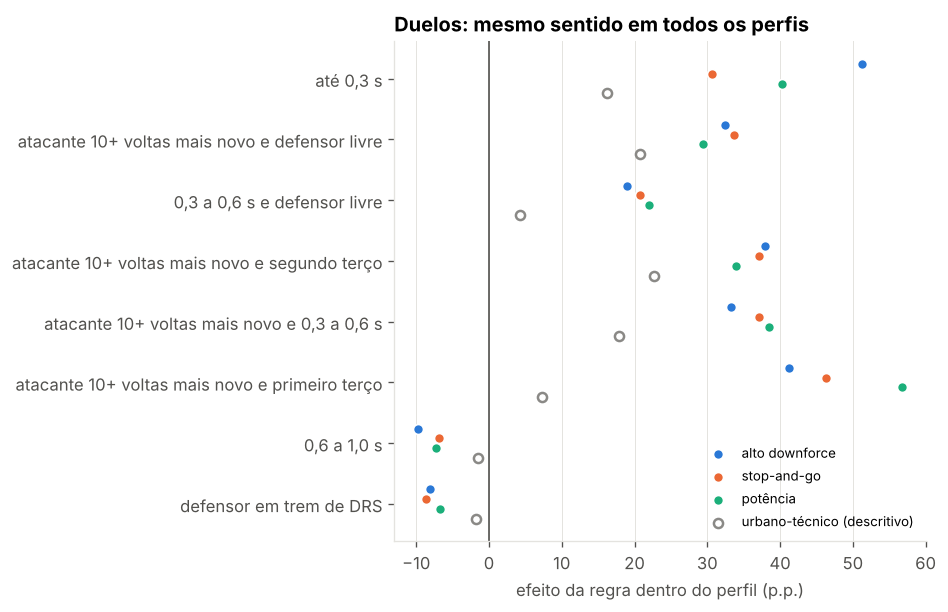

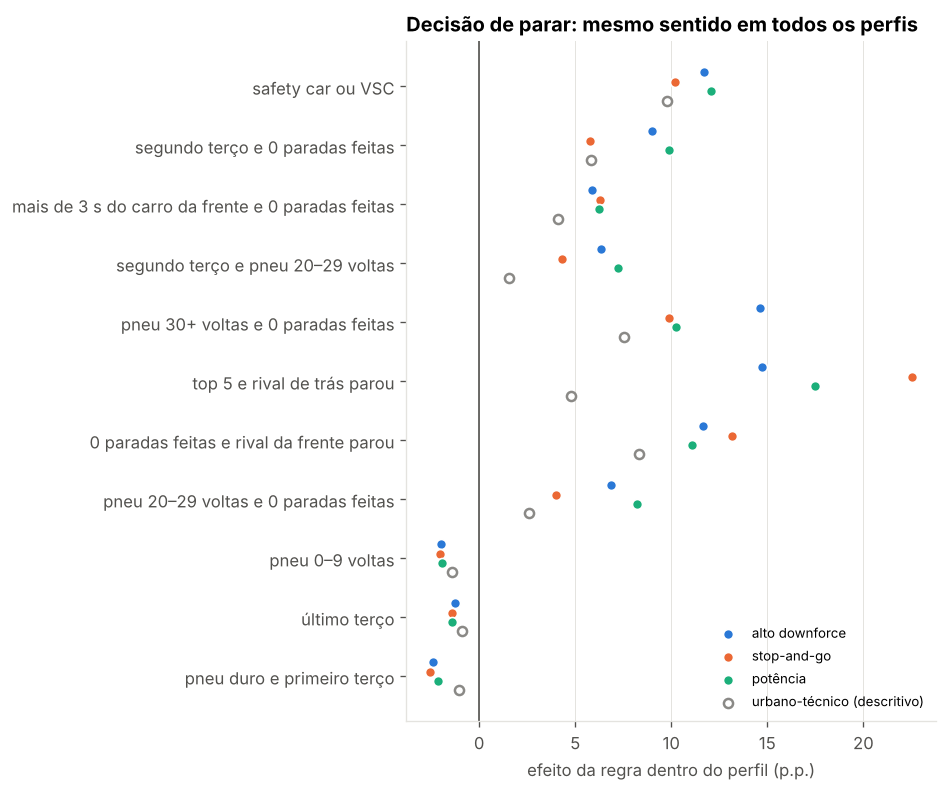

In [24]:
def grafico_abrangencia(caminho, titulo):
    d = pd.read_csv(caminho)
    regras = d.drop_duplicates("ordem").sort_values("ordem")["regra"].tolist()
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(regras) + 1.2))
    desloc = {p: k for p, k in zip(PERFIS, (-0.24, -0.08, 0.08, 0.24))}
    for p in PERFIS:
        sub = d[d["perfil"] == p].set_index("regra").reindex(regras)
        y = np.arange(len(regras)) + desloc[p]
        if p == "urbano-técnico":
            ax.scatter(sub["dif_pp"], y, s=30, facecolors="white", edgecolors=COR[p], linewidths=1.5, label=p + " (descritivo)", zorder=3)
        else:
            ax.scatter(sub["dif_pp"], y, s=36, color=COR[p], edgecolors="white", linewidths=1, label=p, zorder=3)
    ax.axvline(0, color=TINTA_2, linewidth=1)
    ax.set_yticks(range(len(regras)), [rotulo(r) for r in regras]); ax.invert_yaxis()
    ax.set_xlabel("efeito da regra dentro do perfil (p.p.)")
    ax.set_title(titulo); ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()

grafico_abrangencia(DADOS / "abrangencia/duelos_por_perfil.csv", "Duelos: mesmo sentido em todos os perfis")
grafico_abrangencia(DADOS / "abrangencia/parada_por_perfil.csv", "Decisão de parar: mesmo sentido em todos os perfis")

O sentido é o mesmo em todos os perfis; o tamanho varia (por exemplo, "até 0,3 s" vale +51 p.p. no alto downforce e +31 no stop-and-go). A pergunta é se essa variação é maior do que o acaso produziria.

Teste de partições (seção 6.3) para todas as regras, com o p corrigido para o número de regras da análise:

In [25]:
def tabela_testes(caminho):
    t = pd.read_csv(caminho)[["regra", "p_frequencia", "p_efeito", "p_frequencia_corrigido", "p_efeito_corrigido"]].copy()
    t["regra"] = t["regra"].map(rotulo)
    t.iloc[:, 1:] = t.iloc[:, 1:].round(3)
    t.columns = ["regra", "p frequência", "p efeito", "p frequência (corrigido)", "p efeito (corrigido)"]
    return t

display(tabela_testes(DADOS / "abrangencia/duelos_testes.csv"))
tabela_testes(DADOS / "abrangencia/parada_testes.csv")

,regra,p frequência,p efeito,p frequência (corrigido),p efeito (corrigido)
0,"até 0,3 s",0.811,0.045,0.970,0.506
1,atacante 10+ voltas mais novo e defensor livre,0.241,0.904,0.822,1.000
2,"0,3 a 0,6 s e defensor livre",0.783,0.963,1.000,1.000
3,atacante 10+ voltas mais novo e segundo terço,0.392,0.951,0.992,1.000
4,"atacante 10+ voltas mais novo e 0,3 a 0,6 s",0.525,0.942,0.999,1.000
5,atacante 10+ voltas mais novo e primeiro terço,0.009,NaN,0.799,NaN
6,"0,6 a 1,0 s",0.908,0.311,1.000,0.986
7,defensor em trem de DRS,0.007,0.749,0.707,1.000


,regra,p frequência,p efeito,p frequência (corrigido),p efeito (corrigido)
0,safety car ou VSC,0.543,0.824,0.987,0.999
1,segundo terço e 0 paradas feitas,0.837,0.018,1.000,0.387
2,mais de 3 s do carro da frente e 0 paradas feitas,0.895,0.848,1.000,1.000
3,segundo terço e pneu 20–29 voltas,0.863,0.445,1.000,0.762
4,pneu 30+ voltas e 0 paradas feitas,0.543,0.120,0.960,0.855
5,top 5 e rival de trás parou,0.904,0.021,1.000,0.511
6,0 paradas feitas e rival da frente parou,0.701,0.738,1.000,1.000
7,pneu 20–29 voltas e 0 paradas feitas,0.906,0.113,1.000,0.599
8,pneu 0–9 voltas,0.936,0.974,1.000,1.000
9,último terço,0.710,0.849,1.000,1.000


Nenhum p corrigido fica abaixo de 0,05 (o menor é 0,12). Cinco p sem correção ficaram abaixo de 0,05, quando cerca de 2 seriam esperados por acaso em 38 testes; ficam como exploratórios (por exemplo, "até 0,3 s" mais forte no alto downforce e mais trens de DRS na potência).

Teste de poder (seção 6.4) para todas as regras: o menor efeito extra que o teste detecta em 80% das vezes e quanto isso representa do efeito da própria regra.

In [26]:
def tabela_poder(caminho):
    d = pd.read_csv(caminho)
    def celula(r):
        if pd.isna(r["menor_delta_80pct"]):
            return "não chega"
        return f"+{r['subida_efetiva_pp']:.0f} p.p. ({r['como_pct_do_efeito']:.0f}%)"
    d["poder 80%"] = d.apply(celula, axis=1)
    t = d.pivot_table(index=["ordem", "regra"], columns="circuitos_no_grupo",
                      values="poder 80%", aggfunc="first")
    t.columns = [f"grupo de {c} circuitos" for c in t.columns]
    t = t.reset_index(level=0, drop=True)
    t.index = [rotulo(r) for r in t.index]
    return t

display(tabela_poder(DADOS / "abrangencia/poder_duelos_resumo.csv"))
tabela_poder(DADOS / "abrangencia/poder_parada_resumo.csv")

,grupo de 5 circuitos,grupo de 8 circuitos,grupo de 11 circuitos
"até 0,3 s",não chega,+28 p.p. (66%),+28 p.p. (67%)
atacante 10+ voltas mais novo e defensor livre,+27 p.p. (85%),+27 p.p. (85%),+27 p.p. (85%)
"0,3 a 0,6 s e defensor livre",não chega,não chega,não chega
atacante 10+ voltas mais novo e segundo terço,não chega,+28 p.p. (79%),+29 p.p. (80%)
"atacante 10+ voltas mais novo e 0,3 a 0,6 s",não chega,não chega,não chega


,grupo de 5 circuitos,grupo de 8 circuitos,grupo de 11 circuitos
safety car ou VSC,não chega,não chega,não chega
segundo terço e 0 paradas feitas,+7 p.p. (95%),+7 p.p. (98%),+7 p.p. (97%)
mais de 3 s do carro da frente e 0 paradas feitas,+4 p.p. (74%),+5 p.p. (75%),+3 p.p. (45%)
segundo terço e pneu 20–29 voltas,não chega,+7 p.p. (135%),+7 p.p. (133%)
pneu 30+ voltas e 0 paradas feitas,não chega,não chega,não chega
top 5 e rival de trás parou,não chega,não chega,não chega
0 paradas feitas e rival da frente parou,não chega,não chega,não chega
pneu 20–29 voltas e 0 paradas feitas,+8 p.p. (126%),+7 p.p. (128%),+8 p.p. (131%)


O teste só detecta diferenças grandes, em que a regra fica cerca de 1,5 a 2 vezes mais forte num perfil, e em mais da metade das regras nem a maior diferença testada chega a 80%. A causa é estrutural: a unidade é o circuito, e há só 26. Mais voltas não resolvem.

**Conclusão sobre os perfis:** não foi encontrada diferença entre perfis; o teste só detectaria diferenças grandes, então diferenças moderadas não podem ser descartadas. Desenhos alternativos (perfil como descritor na Parte 5, busca dentro de cada perfil na seção 6.1) dão as mesmas regras.

| Teste | O que sorteia | Pergunta |
| --- | --- | --- |
| Permutação | o resultado, dentro de cada corrida | a regra existe? |
| Partições | quais circuitos ficam juntos | a regra muda entre os perfis? |
| Poder | onde e quanto efeito é plantado | o teste de partições veria uma mudança, se ela existisse? |

### 6.6 A descoberta é estável?

A busca inteira foi refeita numa parte dos dados, e as regras foram avaliadas na outra: entre eras (descobre em 2018–21, avalia em 2022+, e o inverso) e em 100 divisões aleatórias dos 26 circuitos em duas metades de 13.

In [27]:
def tabela_estab(caminho):
    t = pd.read_csv(caminho)[["regra", "redescoberta_pct", "mesmo_sentido_fora_pct", "encolhimento_mediano"]].copy()
    t["regra"] = t["regra"].map(rotulo)
    t["encolhimento_mediano"] = t["encolhimento_mediano"].round(2)
    t.columns = ["regra", "redescoberta (% das divisões)", "mesmo sentido fora (%)",
                 "efeito fora ÷ efeito dentro (mediana)"]
    return t

display(tabela_estab(DADOS / "estabilidade/duelos_por_regra.csv"))
tabela_estab(DADOS / "estabilidade/parada_por_regra.csv")

,regra,redescoberta (% das divisões),mesmo sentido fora (%),efeito fora ÷ efeito dentro (mediana)
0,"até 0,3 s",97.0,100.0,0.98
1,atacante 10+ voltas mais novo e defensor livre,100.0,100.0,0.96
2,"0,3 a 0,6 s e defensor livre",100.0,100.0,1.00
3,atacante 10+ voltas mais novo e segundo terço,100.0,100.0,0.97
4,"atacante 10+ voltas mais novo e 0,3 a 0,6 s",100.0,100.0,0.93
5,atacante 10+ voltas mais novo e primeiro terço,7.0,100.0,1.55
6,"0,6 a 1,0 s",100.0,100.0,0.96
7,defensor em trem de DRS,100.0,100.0,1.05


,regra,redescoberta (% das divisões),mesmo sentido fora (%),efeito fora ÷ efeito dentro (mediana)
0,safety car ou VSC,100.0,100.0,0.96
1,segundo terço e 0 paradas feitas,100.0,100.0,1.01
2,mais de 3 s do carro da frente e 0 paradas feitas,100.0,100.0,0.99
3,segundo terço e pneu 20–29 voltas,100.0,100.0,0.99
4,pneu 30+ voltas e 0 paradas feitas,100.0,100.0,1.00
5,top 5 e rival de trás parou,100.0,100.0,0.93
6,0 paradas feitas e rival da frente parou,100.0,100.0,0.92
7,pneu 20–29 voltas e 0 paradas feitas,100.0,100.0,0.96
8,pneu 0–9 voltas,100.0,100.0,1.03
9,último terço,100.0,100.0,0.94


As regras reaparecem em 97% a 100% das divisões, com o mesmo sentido e quase o mesmo tamanho na outra metade. A exceção é "pneu 10+ voltas mais novo e primeiro terço", que é tratada como marginal. A lista final varia um pouco mais, porque a seleção escolhe entre variantes parecidas: cada regra deve ser lida como representante de uma família de padrões.

## 7. Características dos circuitos como descritores: H1–H8 (10 e 11/11)

> **Mensagem:** Nenhuma característica de pista testada explicou o comportamento além do acaso; H1 e H3 ficam como indícios fracos.

*Numeração do projeto, sem relação com as hipóteses (i)–(iii) da proposta.*

Como o rótulo do perfil não acrescentou nada, foram testadas outras características dos circuitos. Em todas:

- critérios escritos antes de rodar e scripts testados com dados sintéticos (sem efeito e com efeito plantado);
- a característica entra como descritor em tercis (baixa, média, alta) entre os 26 circuitos;
- confirmada só se o subgrupo previsto for firme **e** acrescentar em relação à mesma situação de corrida nas outras pistas. O limiar do "acrescenta" vem de 2.000 trocas da característica entre circuitos.

In [28]:
def limiares_acrescenta(caminho):
    lim, atual = {}, None
    for linha in Path(caminho).read_text(encoding="utf-8").splitlines():
        m1 = re.match(r"^(H\w+): alvo", linha)
        if m1:
            atual = m1.group(1)
        m2 = re.search(r"limiar \|z_acr\| ([\d.]+)", linha)
        if m2 and atual and atual not in lim:
            lim[atual] = float(m2.group(1))
    return lim

lim = {}
for pasta in ["sd_features", "sd_pit_lane", "sd_drs"]:
    lim.update(limiares_acrescenta(DADOS / pasta / "saida_completa.txt"))

fontes = {"H1": "sd_features/H1", "H2": "sd_features/H2", "H3": "sd_features/H3",
          "H4": "sd_features/H4", "H5": "sd_features/H5",
          "H6a": "sd_pit_lane/H6a", "H6b": "sd_pit_lane/H6b", "H8": "sd_drs/H8"}
linhas = []
for h, f in fontes.items():
    d = pd.read_csv(DADOS / f"{f}_acrescenta.csv")
    for _, r in d[d["previsto"]].iterrows():
        linhas.append({"hipótese": h, "subgrupo previsto": rotulo(r["descricao"]),
                       "diferença da pista": round(r["diferenca_da_pista"], 3),
                       "z acrescenta": round(r["z_acr"], 2), "limiar": lim.get(h),
                       "firme na busca": bool(r["firme_na_busca"]),
                       "acrescenta": bool(r["acrescenta"])})
hip = pd.DataFrame(linhas)
hip

,hipótese,subgrupo previsto,diferença da pista,z acrescenta,limiar,firme na busca,acrescenta
0,H1,velocidade mínima baixa,0.048,1.81,2.14,False,False
1,H2,"0,6 a 1,0 s e velocidade média alta",-0.015,-2.39,16.10,True,False
2,H2,"velocidade média alta e 0,3 a 0,6 s",-0.006,-0.65,16.10,False,False
3,H3,velocidade média alta,0.066,8.96,9.21,False,False
4,H4,zonas de frenagem alta,-0.020,-7.93,9.46,False,False
5,H5,densidade de curvas alta,0.019,2.97,4.17,False,False
6,H6a,safety car ou VSC e pit lane alta,0.040,7.60,11.98,True,False
7,H6b,segundo terço e pit lane alta,0.008,4.36,11.98,True,False
8,H6b,pneu 20–29 voltas e pit lane alta,0.006,2.34,11.98,True,False
9,H8,"0,3 a 0,6 s e zonas de DRS alta",-0.011,-1.15,13.92,True,False


A coluna "diferença da pista" está na unidade do alvo de cada hipótese: proporção para ultrapassagem, trem de DRS e parada (0,066 = +6,6 p.p.); correlação para H1; % por volta para H4 e H5.

**H1–H5: as features da Etapa 1 como descritores.** No lugar do rótulo, as cinco medidas que geraram os perfis.

| | Previsto | Resultado |
| --- | --- | --- |
| H1 | velocidade mínima baixa → a largada decide mais a chegada | diferença mínima; não confirmada |
| H2 | velocidade média alta → passa-se de mais longe | sem ganho, sentido oposto; não confirmada |
| H3 | velocidade média alta → mais trens de DRS | +6,6 p.p., logo abaixo do limiar (8,96 contra 9,21); não confirmada |
| H4 | mais zonas de frenagem → mais degradação | sentido oposto; não confirmada |
| H5 | mais curvas por km → ritmo menos constante | a medida reprovou na qualidade (0,49 para mínimo de 0,50); não interpretada |

**Erro de processo, registrado na metodologia.** Havia dois critérios escritos antes de rodar: o primeiro era uma correlação de Spearman nos 26 circuitos com correção de Holm; quando a SD passou para o centro, o critério mudou no script, mas o documento não foi atualizado. Pelo critério contínuo, H1 e H3 passam:

In [29]:
for pasta in ["sd_features", "sd_pit_lane", "sd_drs"]:
    atual = None
    for linha in (DADOS / pasta / "resumo.txt").read_text(encoding="utf-8").splitlines():
        m = re.match(r"^(H\w+): ", linha)
        if m:
            atual = m.group(1)
        if "contínuo" in linha and "sem urbanos" not in linha:
            texto = linha.strip().replace("contínuo (informativo): ", "")
            print(f"{atual}: {texto}")

H1: Spearman alvo médio x vel_minima = -0.46, p = 0.0096
H2: Spearman alvo médio x vel_media = -0.02, p = 0.5272
H3: Spearman alvo médio x vel_media = +0.45, p = 0.0109
H4: Spearman alvo médio x zonas_freio = -0.22, p = 0.8604
H5: Spearman alvo médio x densidade_curvas = +0.28, p = 0.0806
H6a: Spearman alvo médio x pit_lane_time_loss_s = +0.20, p = 0.8331
H6b: Spearman alvo médio x pit_lane_time_loss_s = +0.20, p = 0.8331
H8: Spearman alvo médio x zonas_drs = -0.04, p = 0.5888


A diferença entre os critérios vem de que os tercis descartam a informação dentro de cada faixa. Mas as medidas de H1 e H3 não se repetem por circuito entre metades das corridas (−0,05 e −0,02): ficam como indícios fracos, não como hipóteses confirmadas. H1 a H4 foram sugeridas por indícios na mesma base; só H5 era nova.

H4 é informativa: dentro de uma mesma corrida, os setores com mais frenagens por km degradam mais o pneu (Spearman +0,47 em 12 corridas novas). Entre circuitos isso não aparece, provavelmente porque o asfalto domina. É a única ligação confirmada entre o tipo de medida da clusterização e o comportamento de corrida, e vale no nível do setor.

**H6: tempo perdido no pit lane × decisão de parar.** O custo direto da parada, que não entrou na clusterização. H6a (pit lane caro e safety car → para-se mais) teve o sentido certo (16,8% contra 12,8%), firme, mas abaixo do limiar do "acrescenta" (7,60 contra 11,98). H6b (pit lane caro → stints mais longos) foi no sentido oposto. Os circuitos de pit lane médio se desviaram mais que os de pit lane caro, o que não combina com um efeito do custo. Sem Mônaco e Singapura, o quadro é o mesmo.

**H7: comportamento de parada por equipe.** As equipes de ponta (3 primeiras do ano em pontos) reagiriam mais?

In [30]:
h7 = pd.read_csv(DADOS / "equipe_parada/confirmatorio.csv")
t = h7[["hipotese", "situacao", "voltas_ponta", "voltas_outras", "taxa_ponta", "taxa_outras", "diferenca", "p_holm"]].copy()
for c in ["taxa_ponta", "taxa_outras"]:
    t[c] = t[c].map(pct)
t["diferenca"] = (100 * t["diferenca"]).round(1)
t.columns = ["", "situação", "voltas ponta", "voltas outras", "taxa ponta", "taxa outras", "diferença (p.p.)", "p (Holm)"]
display(t.set_index(""))
pd.read_csv(DADOS / "equipe_parada/exploratorio_particoes.csv")[["grupos_testados", "Q_medio_real", "Q_medio_95_aleatoria", "p"]]

,situação,voltas ponta,voltas outras,taxa ponta,taxa outras,diferença (p.p.),p (Holm)
,,,,,,,
H7a,top 5 E rival de trás parou,670,137,"19,3%","27,7%",-8.5,1.0
H7b,SC/VSC (estratificado pela posição),1370,3209,"14,4%","14,0%",-1.2,1.0


,grupos_testados,Q_medio_real,Q_medio_95_aleatoria,p
0,10,1.826287,1.451531,0.001


H7a foi no sentido oposto (as equipes de ponta param menos quando o rival de trás para, no top 5), com só 137 voltas das outras equipes nessa situação. H7b não mostrou diferença. No exploratório, o efeito das regras varia entre as 10 equipes mais do que o acaso (p = 0,001), mas isso está misturado com a posição em que cada equipe costuma andar e não pode ser lido como estilo de equipe.

**H8: zonas de DRS × ultrapassagem.** Tentativa de explicar o efeito de 0,3–0,6 s, a característica de circuito mais estável (Parte 8), com a contagem de zonas de DRS coletada à mão. Os subgrupos previstos foram no sentido oposto e as correlações ficaram perto de zero (−0,04 com a taxa de ultrapassagem e −0,07 com o efeito de 0,3–0,6 s). Só a contagem foi coletada; o comprimento das zonas e a distância até a curva seguinte ficaram de fora.

H6, H7 e H8 foram definidas depois dos resultados anteriores: exploratórias declaradas.

## 8. Onde está a variação entre circuitos (11/11)

> **Mensagem:** Os circuitos diferem de forma estável, mas não pelos perfis; a degradação segue o asfalto.

Os circuitos diferem entre si de forma consistente, mas essa variação não segue os perfis. Foram selecionadas oito medidas de corrida que mantêm a ordem dos circuitos entre metades das corridas e entre as eras. A tabela compara quanto da variação de cada uma o perfil explica (η², de 0 a 1) com quanto agrupamentos sorteados dos mesmos tamanhos explicam.

In [31]:
eta = pd.read_csv(DADOS / "perfil_medidas_estaveis/eta2.csv")
t = eta[eta["versao"] == "sem urbanos (principal)"][["descricao", "eta2", "eta2_mediana_acaso", "p"]].copy()
t[["eta2", "eta2_mediana_acaso", "p"]] = t[["eta2", "eta2_mediana_acaso", "p"]].round(3)
t.columns = ["medida (por circuito, sem Mônaco e Singapura)", "η² do perfil", "η² de grupos sorteados (mediana)", "p"]
t

,"medida (por circuito, sem Mônaco e Singapura)",η² do perfil,η² de grupos sorteados (mediana),p
0,Taxa de ultrapassagem,0.044,0.066,0.630
1,Taxa de parada por volta,0.010,0.068,0.904
2,Idade do pneu na parada,0.020,0.067,0.821
3,Degradação do pneu,0.018,0.067,0.841
4,"Efeito: pneu 10+ mais novo, defensor livre",0.057,0.067,0.557
5,"Efeito: 0,3 a 0,6 s, defensor livre",0.003,0.066,0.975
6,Efeito: defensor em trem de DRS,0.032,0.066,0.725
7,Efeito: 2.º terço e pneu 20–29 voltas,0.019,0.069,0.841


Sem Mônaco e Singapura, o perfil explica menos de 6% de cada medida, abaixo do que grupos sorteados explicam (cerca de 7%). Agrupar os circuitos por essas medidas de corrida também não dá grupos estáveis (concordância de 0,08 entre os agrupamentos de cada metade das corridas, numa escala em que 0 é o acaso).

A medida mais estável de todas é o ganho de atacar a 0,3–0,6 s com o defensor livre (correlação 0,94 entre metades das corridas). O gráfico mostra que ela atravessa os perfis.

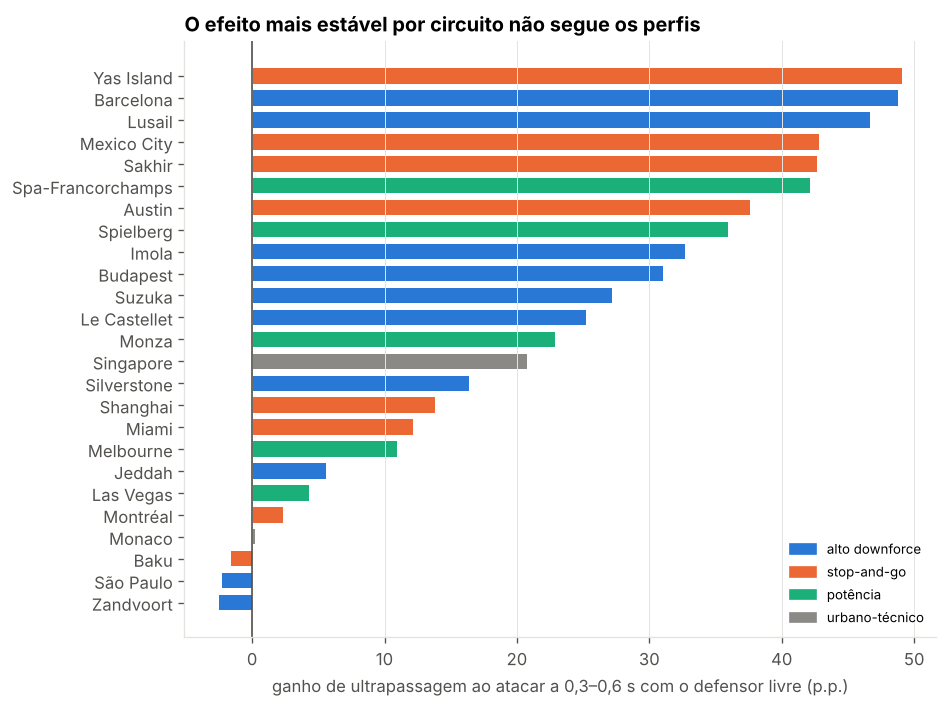

In [32]:
val = pd.read_csv(DADOS / "perfil_medidas_estaveis/valores.csv").rename(columns={"Unnamed: 0": "circuito"})
v = val.sort_values("D3")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(v["circuito"], 100 * v["D3"], color=[COR[p] for p in v["perfil"]], height=0.7)
ax.axvline(0, color=TINTA_2, linewidth=1)
ax.set_xlabel("ganho de ultrapassagem ao atacar a 0,3–0,6 s com o defensor livre (p.p.)")
ax.set_title("O efeito mais estável por circuito não segue os perfis")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR[p], label=p) for p in PERFIS], loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

O efeito vai de praticamente zero (Zandvoort, São Paulo, Baku, Mônaco) a cerca de +49 p.p. (Barcelona, Yas Island), com circuitos de todos os perfis espalhados pela faixa. Nem o perfil nem o número de zonas de DRS (H8, Parte 7) explicam essa diferença.

O que acompanha uma medida de corrida é o asfalto: a degradação dos pneus segue a nota de abrasão da Pirelli, que não entrou na clusterização.

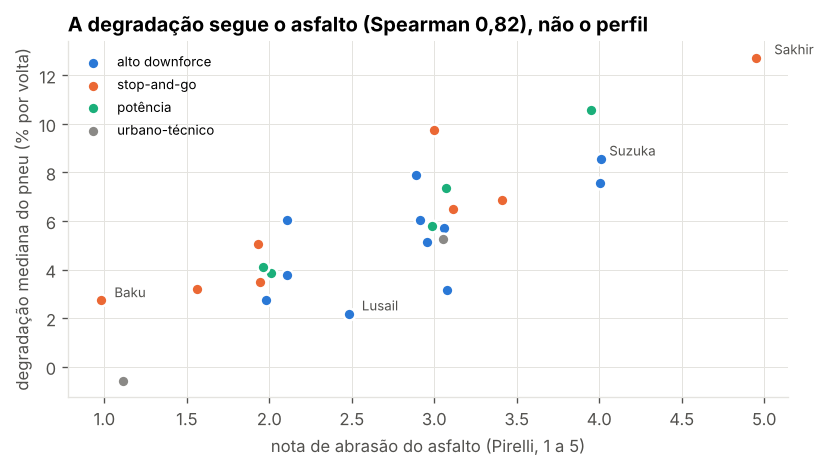

In [33]:
fichas = pd.read_csv(DADOS / "fichas/por_circuito.csv")
feats = pd.read_csv(DADOS / "features_completas_por_circuito.csv")
m = fichas.merge(feats[["circuito", "abrasion"]], on="circuito")
rho = m[["abrasion", "degradacao_mediana_pct_volta"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(7, 4))
jit = np.random.default_rng(1).uniform(-0.12, 0.12, len(m))
for p in PERFIS:
    s = m["perfil"] == p
    ax.scatter(m.loc[s, "abrasion"] + jit[s.values], 100 * m.loc[s, "degradacao_mediana_pct_volta"],
               s=50, color=COR[p], edgecolors="white", linewidths=1.5, label=p, zorder=3)
for nome in ["Baku", "Sakhir", "Suzuka", "Lusail"]:
    r = m[m["circuito"] == nome].iloc[0]
    ax.annotate(nome, (r["abrasion"], 100 * r["degradacao_mediana_pct_volta"]), xytext=(6, 2),
                textcoords="offset points", fontsize=8, color=TINTA_2)
ax.set_xlabel("nota de abrasão do asfalto (Pirelli, 1 a 5)")
ax.set_ylabel("degradação mediana do pneu (% por volta)")
ax.set_title(f"A degradação segue o asfalto (Spearman {num(rho)}), não o perfil")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

Baku e Sakhir são do mesmo perfil (stop-and-go) e têm traçados parecidos, mas o asfalto de Sakhir é o mais abrasivo do calendário e o de Baku um dos menos. O relatório usa outra medida de degradação (descontado o efeito do pneu), com Spearman de +0,75; com a mediana simples por circuito deste gráfico, a relação é ainda mais forte. Ressalva: a nota da Pirelli pode refletir em parte o desgaste já observado.

## 9. Perguntas complementares: safety car e chuva (11/11)

> **Mensagem:** Safety car e chuva também seguem padrões de situação de corrida, sem diferença entre perfis.

Duas perguntas novas de SD, no mesmo método (sem perfil como descritor), definidas depois das análises principais: exploratórias.

### 9.1 Quem ganha e quem perde posição com o safety car (H9 e H11)

- **Evento:** período de safety car em corridas secas (47 períodos, 41 corridas, 22 circuitos; 836 linhas piloto × período).
- **Alvo (H9):** posições ganhas da volta anterior ao safety car até 3 voltas depois da relargada. **H11:** o mesmo, até o fim da corrida.

In [34]:
sc = pd.read_csv(DADOS / "sd_safety_car/subgrupos_finais.csv")
t = sc[sc["final"]][["descricao", "linhas", "circuitos", "media"]].copy()
t["descricao"] = t["descricao"].map(rotulo); t["media"] = t["media"].round(2)
t.columns = ["subgrupo (H9)", "linhas", "circuitos", "posições ganhas até 3 voltas depois"]
display(t)

comp = pd.read_csv(DADOS / "sd_resultado_final/comparacao_h9.csv")
comp["descricao"] = comp["descricao"].map(rotulo)
comp[["ganho_3_voltas", "ganho_fim_da_corrida"]] = comp[["ganho_3_voltas", "ganho_fim_da_corrida"]].round(2)
comp.columns = ["subgrupo", "linhas (quem terminou)", "3 voltas depois", "fim da corrida"]
comp.head(8)

,subgrupo (H9),linhas,circuitos,posições ganhas até 3 voltas depois
0,não parou no SC e algum da frente parou,195,20,1.37
1,11.º em diante e não parou no SC,221,22,1.19
2,parou no SC,347,21,-0.87
3,6.º a 10.º e parou no SC,93,17,-1.66
4,não parou no SC e mais de 3 s do carro de trás,178,22,1.07
5,não parou no SC,489,22,0.62
6,parou no SC e até 1 s do carro de trás,65,17,-1.66
7,não parou no SC e até 1 s do carro da frente,167,17,0.97
8,algum da frente parou e pneu 0–9 voltas,178,20,0.92
9,pneu 0–9 voltas e mais de 3 s do carro de trás,143,20,0.97


,subgrupo,linhas (quem terminou),3 voltas depois,fim da corrida
0,não parou no SC e algum da frente parou,171,1.43,0.65
1,11.º em diante e não parou no SC,172,1.35,1.40
2,parou no SC,308,-0.80,-0.31
3,6.º a 10.º e parou no SC,86,-1.49,-1.23
4,não parou no SC e mais de 3 s do carro de trás,149,1.12,0.95
5,não parou no SC,420,0.66,0.23
6,parou no SC e até 1 s do carro de trás,56,-1.64,-0.59
7,não parou no SC e até 1 s do carro da frente,145,1.07,0.27


Quem fica na pista herda as posições de quem parou logo depois da relargada; quem para perde. Até o fim da corrida, parte dessa perda volta com o pneu mais novo (de −0,80 para −0,31, deixando de ser significativo), menos no meio do pelotão (6.º a 10.º), onde a perda se mantém. O padrão mais forte no fim da corrida é de posição: quem estava do 11.º para trás ganha, o que é compatível com carros rápidos fora de posição recuperando (não testado contra corridas sem safety car).

In [35]:
part_sc = pd.read_csv(DADOS / "perfil_safety_car/teste_particoes.csv")
part_sc[["analise", "Q_medio_real", "Q_95_acaso", "p"]].round(3)

,analise,Q_medio_real,Q_95_acaso,p
0,H9 (3 voltas),0.980,1.189,0.313
1,H11 (fim da corrida),0.814,1.019,0.419
2,poder: +1 em parou no SC só em alto downforce,1.525,1.417,0.020
3,poder: +2 em parou no SC só em alto downforce,2.610,1.942,0.001


O teste de partições confirma o mesmo quadro: os padrões do safety car não dependem do perfil (p = 0,31 e 0,42). As linhas de poder mostram que uma diferença de 1 posição concentrada num perfil seria detectada (p = 0,02); diferenças menores, não.

### 9.2 Chuva: quando se troca de pneu (H10)

16 corridas com pneu intermediário ou de chuva. Linha: piloto em uma volta. Alvo: trocou para pneu de chuva (entrar) ou para pneu seco (sair).

In [36]:
for nome, f in [("entrar no pneu de chuva", "H10a_entrar"), ("sair para o pneu seco", "H10b_sair")]:
    d = pd.read_csv(DADOS / f"sd_chuva/{f}_subgrupos.csv")
    t = d[d["final"]][["descricao", "linhas", "eventos", "media"]].copy()
    t["descricao"] = t["descricao"].map(rotulo); t["media"] = t["media"].map(pct)
    t.columns = [f"subgrupo ({nome})", "voltas", "corridas", "taxa de troca por volta"]
    display(t)

,subgrupo (entrar no pneu de chuva),voltas,corridas,taxa de troca por volta
0,pelotão já no pneu de destino: 1/3 a 2/3 e último terço,33,4,"51,5%"
1,pelotão já no pneu de destino: 1/3 a 2/3 e chovendo,52,6,"42,3%"


,subgrupo (sair para o pneu seco),voltas,corridas,taxa de troca por volta
0,ritmo: destino mais rápido e sem chuva,195,8,"26,2%"
1,pelotão já no pneu de destino: até 1/3 e sem chuva,632,9,"14,4%"
2,pelotão já no pneu de destino: 1/3 a 2/3 e segundo terço,30,6,"50,0%"
4,pelotão já no pneu de destino: até 1/3,1025,13,"10,4%"
6,ritmo: destino mais lento,344,10,"12,2%"
9,pelotão já no pneu de destino: 1/3 a 2/3,149,10,"15,4%"
14,pelotão já no pneu de destino: nenhum,5122,14,"1,1%"
17,pneu 20+ voltas e safety car ou VSC,134,4,"14,2%"


As equipes trocam acompanhando o pelotão: quando de um a dois terços dos outros já trocaram e está chovendo, a taxa de troca por volta passa de 40%. Para voltar ao seco, pesa o ritmo de quem já está no pneu de destino. Cada subgrupo depende de 4 a 13 corridas: resultado frágil, só descritivo.

## 10. Fechando as hipóteses originais (14 e 15/11)

> **Mensagem:** Rodadas na forma original, as hipóteses (i) e (ii) da proposta também não encontram efeito do perfil.

As hipóteses (i) e (ii) nunca tinham rodado exatamente como estavam na proposta: a (i) foi absorvida pela (ii) reformulada, e a (ii) perdeu o piloto como descritor por falta de suporte. Para fechar as duas, elas foram rodadas na forma original, com critérios fixados antes. São exploratórias: definidas depois de todas as outras análises, na mesma base.

### 10.1 Hipótese (i): estratégia → posições ganhas

Rodada em 14/11. Mesmas 2.718 linhas e mesmos descritores da rodada 2. Alvo: posições ganhas (largada − chegada, reordenadas entre quem terminou), descontada a média de quem largou na mesma posição.

In [37]:
h1i = pd.read_csv(DADOS / "sd_h1_posicoes_ganhas/subgrupos_base_real.csv")
res_h1i = pd.read_csv(DADOS / "sd_h1_posicoes_ganhas/resumo_base_real.csv")
display(res_h1i[["linhas", "descricoes", "elegiveis", "limiar_z", "firmes", "finais", "perfil_acrescenta"]]
        .rename(columns={"descricoes": "subgrupos", "limiar_z": "limiar |z|",
                         "perfil_acrescenta": "perfil acrescenta em"}))

t = h1i[h1i["final"]][["descricao", "linhas", "media", "z"]].copy()
t["descricao"] = t["descricao"].map(rotulo)
t[["media", "z"]] = t[["media", "z"]].round(2)
t.columns = ["subgrupo final", "linhas", "posições a mais que o normal para a largada", "z"]
t

,linhas,subgrupos,elegiveis,limiar |z|,firmes,finais,perfil acrescenta em
0,2718,688,644,3.486713,164,7,0


,subgrupo final,linhas,posições a mais que o normal para a largada,z
0,parou mais que o pelotão,451,-1.81,-12.56
12,parou antes do pelotão,906,-0.82,-8.03
27,parou depois do pelotão,906,0.71,6.94
39,largou 6-10 e parou antes do pelotão,228,-1.26,-6.23
53,largou duro,286,0.96,5.31
85,parou igual ao pelotão,2050,0.32,4.69
149,parou menos que o pelotão,217,0.77,3.71


O perfil acrescentou efeito em 0 dos 164 subgrupos firmes, então a hipótese (i) como estava na proposta ("estratégias rendem mais em certos perfis") não se confirma. Sem o perfil, aparecem padrões de estratégia: parar depois do pelotão acompanha ganho de posições, parar antes acompanha perda, e largar de pneu duro rende cerca de 1 posição. A leitura precisa de cautela: "parou antes" mistura estratégia com parada forçada (dano e furo costumam ser cedo), e "parou depois" mistura escolha com ritmo, porque quem anda bem consegue esticar o stint.

### 10.2 Hipótese (ii) na forma original: piloto/equipe × perfil, mesmo sem suporte

A versão com o piloto como descritor foi rodada assim mesmo, com o suporte mínimo reduzido de propósito para 10 linhas. Mesmas 2.718 linhas; alvo original (posição contra o próprio normal, sem descontar a largada); descritores: piloto, equipe e perfil. Uma afinidade só seria confirmada se o subgrupo passasse do limiar e o perfil acrescentasse em relação ao mesmo piloto (ou equipe) nos outros perfis.

O teste sintético mostrou que o desenho funciona: com +3 posições plantadas num par piloto × perfil de 47 linhas, o par foi o único firme, e o perfil acrescentou.

Na base real, nada passou. As saídas desta busca (`sd_h2_piloto_perfil`) ainda não estão no repositório; a tabela vem do registro da análise.

| Maiores valores (nenhum acima do limiar) | Linhas | Posições acima do normal | z (limiar 3,77) | z acrescenta (limiar 3,87) |
| --- | --- | --- | --- | --- |
| Equipe Racing Bulls e stop-and-go | 13 | −3,03 | −3,12 | −3,22 |
| Tsunoda e stop-and-go | 29 | +1,90 | +2,87 | +3,40 |
| Equipe AlphaTauri e stop-and-go | 34 | +1,74 | +2,86 | +3,35 |
| Equipe Red Bull Racing e stop-and-go | 85 | +1,05 | +2,69 | +2,75 |
| Equipe Alpine e alto downforce | 77 | +0,90 | +2,20 | +2,94 |

No urbano-técnico, o maior valor foi da Ferrari (25 linhas, +1,28 posição, z 1,75). Uma afinidade grande (cerca de 3 posições num par de 50 linhas) teria sido encontrada; afinidades menores, ou em pares menores como os do urbano-técnico, não seriam. A busca confirma a decisão de setembro: a falta de suporte não escondia afinidades grandes.

## 11. Síntese

**O que a Etapa 2 encontrou**

1. **Padrões de corrida claros e estáveis.** Ultrapassagem: distância curta, pneu bem mais novo e defensor fora de trem de DRS. Parada: safety car, pneu velho sem ter parado, meio da corrida e reação ao rival. As regras se repetem em outra era e com outra metade dos circuitos.
2. **Os padrões valem em todos os perfis.** Mesmo sentido em todos; as diferenças de tamanho não passam do que grupos sorteados produzem. O teste só detectaria diferenças grandes, então diferenças moderadas não estão descartadas.
3. **Os circuitos diferem, mas não pelos perfis.** A variação entre circuitos é estável e grande, atravessa os perfis e, no caso da degradação, acompanha o asfalto.
4. **Nenhuma característica de pista testada explicou o comportamento além do acaso** (features da Etapa 1, pit lane, equipe, DRS), com indícios fracos em H1 e H3 pelo critério contínuo.

**Por que as ligações entre pista e comportamento não se confirmaram**

- A amostra efetiva é de 26 circuitos, não de milhares de voltas: só efeitos grandes aparecem.
- Dentro de cada perfil, a variação é maior que entre perfis.
- A clusterização mede o traçado na volta de classificação; o comportamento de corrida parece depender mais do asfalto, de detalhes do traçado que essas medidas não captam e, sobretudo, da situação da corrida.
- As regras são gerais: estar a 0,3 s ajuda em qualquer pista. Isso é um resultado, não uma falha.

**Limitações e decisões registradas na metodologia**

- A tipologia foi derivada sem 2022 e aplicada a corridas de 2022.
- Abandonos tratados sem distinguir batida de quebra.
- Era como descritor nos duelos (desvio da proposta).
- Ajustes decididos depois de ver resultados: exclusão das voltas de bandeira vermelha; exclusão de variações aninhadas na seleção das regras; perfis sorteados no teste de poder.
- Os dois critérios de H1–H5, com os resultados nos dois.
- H1–H4 sugeridas por indícios na mesma base; H6–H11 e as hipóteses (i) e (ii) na forma original são exploratórias.
- A nota de abrasão pode refletir o desgaste observado.
- Todas as análises mostram associação, não causa.

**Em um minuto**

> A SD encontrou padrões robustos de ultrapassagem e de decisão de parada, que se repetem em outra era e com outra metade dos circuitos. Medi a abrangência deles pelos perfis da Etapa 1: valem igualmente nos perfis, e as diferenças entre perfis são do tamanho das que grupos sorteados produzem. Tentei ligar características de pista ao comportamento por outros caminhos (features da clusterização, pit lane, equipe, zonas de DRS) e nada se confirmou com os critérios fixados antes. Os circuitos diferem de forma estável, mas essa variação não segue a tipologia, que mede traçado; o que acompanha a degradação é o asfalto. A Etapa 1 serve para mostrar que os padrões estratégicos são gerais, não para separá-los.